STEP1: Setup

Figure Parameters

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="paper", palette="colorblind")
plt.rcParams.update({"font.size": 20, "axes.titlesize": 20, "axes.labelsize": 16, "xtick.labelsize": 10, "ytick.labelsize": 10})
plt.rcParams["figure.dpi"] = 300

Importing Libraries

In [ ]:
import os
import scanpy as sc
import pandas as pd
import numpy as np

Import Data

In [ ]:
data_dir      = "/Volumes/TOSHIBA EXT/Nowotny/ENV1/head"
BARCODES_CSV  = f"/{data_dir}/../csv_saves/N_barcodes.csv"
OUTPUT_H5AD   = "tumour_cells.h5ad"

In [ ]:
barcodes = pd.read_csv(BARCODES_CSV, index_col=0)
barcodes["patient_tag"] = barcodes["patient_id"].str.split("_", n=1).str[1]
barcodes["raw_bc"] = [
    idx.rsplit(f"-{tag}", 1)[0]
    for idx, tag in zip(barcodes.index, barcodes["patient_tag"])]

print("Barcode table prepared:")
print(barcodes[["patient_id", "patient_tag", "raw_bc", "condition", "cl_annotation"]].head(5))
print(f"Total tumour barcodes: {len(barcodes)}\n")

In [ ]:
barcodes["patient_id_norm"] = (barcodes["patient_id"].str.replace("-", "_", regex=False))

In [ ]:
adatas  = []
skipped = []

for fname in sorted(os.listdir(data_dir)):
    if not fname.endswith(".h5ad") or fname.startswith("._"):
        continue

    file_stem       = fname.replace(".h5ad", "")
    patient_id      = file_stem
    patient_id_norm = patient_id.replace("-", "_")
    sample_bc = barcodes[barcodes["patient_id_norm"] == patient_id_norm]

    if len(sample_bc) == 0:
        skipped.append(fname)
        continue   # Normal (N-) samples land here

    adata = sc.read_h5ad(os.path.join(data_dir, fname))

    # Matching raw 10x barcodes against adata.obs_names
    mask = adata.obs_names.isin(sample_bc["raw_bc"])

    if mask.sum() == 0:
        print(f"  [{fname}] no barcode overlap")
        print(f"     CSV barcodes:    {sample_bc['raw_bc'].iloc[:3].tolist()}")
        print(f"     adata.obs_names: {adata.obs_names[:3].tolist()}")
        skipped.append(fname)
        continue

    subset = adata[mask].copy()

    # ── Downsampling oversized samples ──────────────────────────────────────
    MAX_CELLS = 6000
    if subset.n_obs > MAX_CELLS:
        np.random.seed(42)
        keep_idx = np.random.choice(subset.obs_names, size=MAX_CELLS, replace=False)
        subset   = subset[keep_idx].copy()
        print(f"  [{patient_id}] downsampled to {MAX_CELLS} cells")

    # ── Assigning metadata──────────────────────────────────────
    # Index sample_bc by raw_bc so .reindex() aligns on barcode safely
    sample_bc_idx = sample_bc.set_index("raw_bc")
    matched       = sample_bc_idx.reindex(subset.obs_names)  # preserves cell order

    # Warn if any barcodes failed to match
    n_unmatched = matched["condition"].isna().sum()
    if n_unmatched > 0:
        print(f"  WARNING [{patient_id}]: {n_unmatched}/{len(subset)} cells "
              f"had no metadata match — check barcode format")
        print(f"     subset sample:   {subset.obs_names[:3].tolist()}")
        print(f"     CSV bc sample:   {sample_bc['raw_bc'].iloc[:3].tolist()}")

    subset.obs["sample"]       = patient_id
    subset.obs["condition"]    = matched["condition"].values
    subset.obs["scVI_leiden"]  = matched["scVI_leiden"].values
    subset.obs["cl_annotation"] = matched["cl_annotation"].values

    # ── Keep only relevant obs columns ────────────────────────────────────
    keep_obs = ["sample", "condition", "total_counts",
                "n_genes_by_counts", "scVI_leiden", "cl_annotation"]
    subset.obs = subset.obs[keep_obs].copy()

    # ── Sanity-check X is raw counts ──────────────────────────────────────
    subset.layers = {"counts": subset.layers["counts"]}
    x = subset.X.toarray() if hasattr(subset.X, "toarray") else subset.X
    assert np.allclose(x, np.round(x), atol=1e-3), (
        f"{fname}: X does not look like raw counts "
        f"(min={x.min():.2f}, max={x.max():.2f})"
    )

    # ── Prefix obs_names with patient_id last (after all mapping) ─────────
    subset.obs_names = [f"{patient_id}_{bc}" for bc in subset.obs_names]

    adatas.append(subset)
    print(
        f"  {patient_id}: {mask.sum():>4d} matched cells "
        f"(of {len(sample_bc)} in CSV),  "
        f"condition: {subset.obs['condition'].iloc[0]}"
    )

print(f"\nDone. {len(adatas)} samples loaded, {len(skipped)} skipped.")
print(barcodes["patient_id"].unique()[:20])

Step2: Concatenation

In [ ]:
#concatenation
print(f"Loaded:  {len(adatas)} samples")
print(f"Skipped: {len(skipped)}")
if skipped:
    print(f"Skipped files: {skipped}")

tumour = sc.concat(adatas, merge="same")

print(f"\nTotal tumour cells : {tumour.n_obs}")
print(f"Total genes        : {tumour.n_vars}")
print(f"\n{tumour.obs['condition'].value_counts()}")

In [ ]:
#saving concatenated progress
tumour.obs_names_make_unique()
tumour.write("Adata_Saves/tumour_raw.h5ad")

In [ ]:
deliberate break -> RESTART KERNEL TO Save Memory

Step 3: Simple Cell Filter

Figure Parameters

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="paper", palette="colorblind")
plt.rcParams.update({"font.size": 20, "axes.titlesize": 20, "axes.labelsize": 16, "xtick.labelsize": 10, "ytick.labelsize": 10})
plt.rcParams["figure.dpi"] = 300

condition_palette = {"HER2": "#2CA02C", "HER2+": "#2CA02C", "TN": "#976391", "ER": "#F46036", "ER+": "#F46036", "N2": "#031A6B", "N": "#031A6B"}

celltype_palette = {
    #immune compartments
    "T Cells": "#2166AC",#deep blue
    "B Cells": "#FFD92F",#bright yellow
    "Plasma Cells": "#FF7F00",#orange
    "Macrophages": "#33A02C",#green
    "Mast Cells": "#8C510A",#brown
    "Dendritic Cells": "#6A3D9A",#violet-purple

    #stromal compartments
    "Fibroblasts": "#D73027",#red
    "Endothelial Cells": "#F781BF",#pink

    #epithelial compartments
    "Epithelial": "#00BFC4",#turquoise
    "Epithelial: Luminal Progenitor": "#A6CEE3",#light cyan
    "Epithelial: Mature Luminal": "#1F9E89",#teal
    "Epithelial: Basal": "#00441B",#dark green-teal

    # fallback
    "Unknown": "#808080"#grey
}

Importing Libraries

In [2]:
import os
import scanpy as sc
import pandas as pd
import numpy as np
import gseapy as gp
import gc
import scipy.sparse as sp

In [3]:
data_dir      = "/Volumes/TOSHIBA EXT/Nowotny/ENV1/head"

In [4]:
import rpy2.robjects as ro
import logging
import rpy2.rinterface_lib.callbacks as rcb

sc.settings.verbosity = 0
rcb.logger.setLevel(logging.ERROR)

Error importing in API mode: ImportError("dlopen(/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so, 0x0002): Library not loaded: @rpath/R/lib/libR.dylib\n  Referenced from: <CBEF4F67-1D94-3EA0-88C4-F34EBE0600C2> /Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so\n  Reason: tried: '/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/../../R/lib/R/lib/libR.dylib' (no such file), '/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/../../R/lib/libR.dylib' (no such file), '/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/../../R/lib/R/lib/libR.dylib' (no such file), '/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/../../R/lib/libR.dylib' (no such file), '/Users/gernotstuhler/miniforge3_arm64/envs/scFates/bin/../lib/R/lib/libR.dylib' (no such file), '/Users/g

Iporting Concatenated Adata

In [5]:
import psutil

tumour = sc.read_h5ad("Adata_Saves/tumour_raw.h5ad")
print(f"Available RAM: {psutil.virtual_memory().available / 1e9:.1f} GB")
print(tumour)

Available RAM: 0.9 GB
AnnData object with n_obs × n_vars = 133240 × 33538
    obs: 'sample', 'condition', 'total_counts', 'n_genes_by_counts', 'scVI_leiden', 'cl_annotation'
    var: 'mt', 'ribo', 'hb'
    layers: 'counts'


Filtering, Normalisation

Simple Filtering

In [6]:
#Filtering genes
sc.pp.filter_genes(tumour, min_cells=20)
print(f"Genes after filter: {tumour.n_vars:,}")   #expect ~10-15k

#saving raw
tumour.layers["counts"] = tumour.X.copy()
sc.pp.normalize_total(tumour, target_sum=1e4, inplace=True)
sc.pp.log1p(tumour)
tumour.layers["lognorm"] = tumour.X.copy()

Genes after filter: 23,400


OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


In [7]:
print(tumour.shape)
print("ROR1" in tumour.var_names, "ROR2" in tumour.var_names)
print([g for g in tumour.var_names if "ROR1" in str(g).upper()])

(133240, 23400)
True True
['ROR1', 'ROR1-AS1']


Step4: New HVG Selection

In [8]:
%load_ext rpy2.ipython

In [9]:
%%R
library(Matrix)
library(scry)
library(SingleCellExperiment)
library(rsvd)

Loading required package: SummarizedExperiment
Loading required package: MatrixGenerics
Loading required package: matrixStats

Attaching package: ‘MatrixGenerics’

The following objects are masked from ‘package:matrixStats’:

    colAlls, colAnyNAs, colAnys, colAvgsPerRowSet, colCollapse,
    colCounts, colCummaxs, colCummins, colCumprods, colCumsums,
    colDiffs, colIQRDiffs, colIQRs, colLogSumExps, colMadDiffs,
    colMads, colMaxs, colMeans2, colMedians, colMins, colOrderStats,
    colProds, colQuantiles, colRanges, colRanks, colSdDiffs, colSds,
    colSums2, colTabulates, colVarDiffs, colVars, colWeightedMads,
    colWeightedMeans, colWeightedMedians, colWeightedSds,
    colWeightedVars, rowAlls, rowAnyNAs, rowAnys, rowAvgsPerColSet,
    rowCollapse, rowCounts, rowCummaxs, rowCummins, rowCumprods,
    rowCumsums, rowDiffs, rowIQRDiffs, rowIQRs, rowLogSumExps,
    rowMadDiffs, rowMads, rowMaxs, rowMeans2, rowMedians, rowMins,
    rowOrderStats, rowProds, rowQuantiles, rowRanges, ro

In [10]:
def scipy_csc_to_r_dgc(mat):
    mat = mat.tocsc()
    i = ro.IntVector(mat.indices)
    p = ro.IntVector(mat.indptr)
    x = ro.FloatVector(mat.data)
    dims = ro.IntVector(mat.shape)
    return ro.r["new"]("dgCMatrix", i=i, p=p, x=x, Dim=dims)

conditions = tumour.obs["sample"].unique()

deviance_df = pd.DataFrame(index=tumour.var_names)

for cond in conditions:

    print(f"Processing {cond}")

    ad = tumour[tumour.obs["sample"] == cond].copy()

    counts = ad.layers["counts"].T
    counts_r = scipy_csc_to_r_dgc(counts)

    ro.globalenv["raw_counts"] = counts_r
    ro.globalenv["gene_names"] = ro.StrVector(ad.var_names)
    ro.globalenv["cell_names"] = ro.StrVector(ad.obs_names)

    ro.r("""
        library(Matrix)
        library(SingleCellExperiment)
        library(scry)

        rownames(raw_counts) <- gene_names
        colnames(raw_counts) <- cell_names

        sce <- SingleCellExperiment(
            assays = list(counts = raw_counts)
        )

        sce <- devianceFeatureSelection(sce)

        binomial_deviance <- rowData(sce)$binomial_deviance
    """)

    deviance_df[cond] = np.array(ro.r["binomial_deviance"])

Processing GSM4909253_N-PM0092-Total
Processing GSM4909254_N-PM0019-Total
Processing GSM4909257_N-PM0095-Total
Processing GSM4909261_N-PM0230-Total
Processing GSM4909263_N-MH0064-Total
Processing GSM4909265_N-PM0233-Total
Processing GSM4909266_N-MH0169-Total
Processing GSM4909268_N-MH0023-Total
Processing GSM4909270_N-PM0342-Total
Processing GSM4909271_N-MH288-Total
Processing GSM4909272_N-MH0021-Total
Processing GSM4909274_N-MH275-Total
Processing GSM4909276_N-PM0372-Total
Processing GSM4909281_TN-MH0126
Processing GSM4909282_TN-MH0135
Processing GSM4909283_TN-SH0106
Processing GSM4909284_TN-MH0114-T2
Processing GSM4909285_TN-B1-MH4031
Processing GSM4909286_TN-B1-MH0131
Processing GSM4909287_TN-B1-Tum0554
Processing GSM4909288_TN-B1-MH0177
Processing GSM4909289_HER2-AH0308
Processing GSM4909290_HER2-PM0337
Processing GSM4909291_HER2-MH0031
Processing GSM4909292_HER2-MH0069
Processing GSM4909293_HER2-MH0161
Processing GSM4909294_HER2-MH0176
Processing GSM4909295_ER-AH0319
Processing GS

In [11]:
#binomial_deviance = np.array(ro.r["binomial_deviance"])
tumour.var["binomial_deviance"] = deviance_df.max(axis=1)#using max: Each subtype-specific marker is retained because it is highly deviant in at least one condition. instead of mean: I want genes that are consistently informative across all conditions
binomial_deviance = tumour.var["binomial_deviance"].values

In [12]:
feat_genes = (tumour.var.get("mt", False)
        | tumour.var.get("ribo", False)
        | tumour.var.get("hb", False))

exclude_mask = feat_genes

binomial_deviance = tumour.var["binomial_deviance"].values

ranked_idx = np.argsort(binomial_deviance)[::-1]
filtered_idx = [i for i in ranked_idx if not exclude_mask.iloc[i]]

N = 4000
selected_idx = filtered_idx[:N]


In [13]:
import pandas as pd

gavish_df = pd.read_excel("Input_Dataframes/Gavish_cell_state_signature.xlsx")
gavish_states = {}

for state in gavish_df.columns:
    genes = (gavish_df[state]
        .dropna()
        .astype(str)
        .str.strip())
    genes = genes[genes != ""]
    gavish_states[state] = genes.unique().tolist()

print(f"Loaded {len(gavish_states)} cell states:")
for state, genes in gavish_states.items():
    print(f"{state}: {len(genes)} genes")

gavish_genes = sorted({gene
    for genes in gavish_states.values()
    for gene in genes})

print(f"Total unique Gavish genes: {len(gavish_genes)}")

Loaded 41 cell states:
MP1  Cell Cycle - G2/M: 50 genes
MP2  Cell Cycle - G1/S: 50 genes
MP3  Cell Cylce HMG-rich: 50 genes
MP4  Chromatin : 50 genes
MP5 Stress : 50 genes
MP6 Hypoxia: 50 genes
MP7 Stress (in vitro): 50 genes
MP8 Proteasomal degradation: 50 genes
MP9 Unfolded protein response: 50 genes
MP10 Protein maturation: 50 genes
MP11 Translation initiation: 50 genes
MP12 EMT-I: 50 genes
MP13 EMT-II: 50 genes
MP14 EMT-III : 50 genes
MP15 EMT IV: 50 genes
MP16 MES (glioma): 50 genes
MP17 Interferon/MHC-II (I): 50 genes
MP18 Interferon/MHC-II (II): 50 genes
MP19 Epithelial Senescence: 50 genes
MP20 MYC: 50 genes
MP21 Respiration: 50 genes
MP22 Secreted I: 50 genes
MP23 Secreted II: 50 genes
MP24 Cilia: 50 genes
MP25 Astrocytes: 50 genes
MP26 NPC Glioma: 50 genes
MP27 Oligo Progenitor: 50 genes
MP28 Oligo normal: 50 genes
MP29 NPC/OPC: 50 genes
MP30 PDAC-classical: 50 genes
MP31 Alveolar: 50 genes
MP32 Skin-pigmentation: 50 genes
MP33 RBCs: 50 genes
MP34 Platelet-activation: 50 gene

In [14]:
#Adding Genes of interest and Gavish Genes to the list of Highly Variable Genes
genes_oi = ["ROR1", "ROR2", "EGFR", "ERBB2", "EPCAM"]#genes of interest
protected_genes = list(
    set(genes_oi + gavish_genes))

print(f"Total protected genes: {len(protected_genes)}")
mask = np.zeros(tumour.n_vars,dtype=bool)

# top deviant genes
mask[selected_idx] = True
# retain Gavish + ROR1/EGFR genes
missing = []
for gene in protected_genes:
    if gene in tumour.var_names:
        mask[tumour.var_names.get_loc(gene)] = True
    else:
        missing.append(gene)
print(f"Missing protected genes: {len(missing)}")
print(missing[:20])

tumour.var["highly_deviant"] = mask
tumour.var["highly_variable"] = tumour.var["highly_deviant"]

print(f"Selected genes: {tumour.var['highly_variable'].sum()}")
print(tumour.var_names[tumour.var["highly_variable"]][:20])

top_genes = tumour.var_names[tumour.var["highly_deviant"]]
pd.Series(top_genes).to_csv("Dataframe_Saves/top4000_deviant_genes.csv", index=False, header=False)

Total protected genes: 1551
Missing protected genes: 92
['SEPP1', 'DUOXA2', 'PTPRCAP', 'MYEOV2', 'C10ORF10', 'C1ORF228', 'SFTPC', 'LHFPL3', 'DPCR1', 'KLHL4', 'LPPR1', 'C11ORF1', 'CRHBP', 'PMP2', 'C15ORF48', 'IGLC1', 'IGLJ3', 'CDH17', 'C5ORF46', 'OLIG2']
Selected genes: 4506
Index(['NOC2L', 'HES4', 'ISG15', 'SDF4', 'UBE2J2', 'MXRA8', 'AURKAIP1',
       'MRPL20', 'VWA1', 'SSU72', 'GNB1', 'FAAP20', 'RER1', 'TNFRSF14',
       'CAMTA1', 'PARK7', 'ERRFI1', 'ENO1', 'CTNNBIP1', 'RBP7'],
      dtype='object')


In [15]:
#sanity check
retained_gavish = [
    g for g in gavish_genes
    if g in tumour.var_names[mask]]

missing_gavish = [
    g for g in gavish_genes
    if g not in tumour.var_names[mask]]

print(f"Retained Gavish genes: {len(retained_gavish)}/{len(gavish_genes)}")
print("Missing:",missing_gavish[:20])

Retained Gavish genes: 1455/1547
Missing: ['AC010343.1', 'AC012181.2', 'AC068631.2', 'AC134669.2', 'ATP5E', 'ATP5G1', 'ATP5G3', 'ATP5I', 'ATP5J2', 'AVP', 'C10ORF10', 'C11ORF1', 'C11ORF54', 'C11ORF88', 'C12ORF75', 'C15ORF48', 'C16ORF89', 'C19ORF33', 'C19ORF48', 'C19ORF77']


Step 5: ALRA Imputation

Characterising Transcript Dropout

In [16]:
import matplotlib.gridspec as gridspec

#Extracting raw counts for ROR1 and comparison genes
comparison_genes = {
    "ROR1":   "Target gene (surface receptor)",
    "EPCAM":  "Epithelial marker (positive control)",
    "MKI67":  "Proliferation marker (positive control)",
    "ACTB":   "Housekeeping gene (positive control)",
    "EGFR":   "Surface receptor (same class as ROR1)",
    "ERBB2":  "Surface receptor (same class as ROR1)"}

comparison_genes = {g: desc for g, desc in comparison_genes.items()
    if g in tumour.var_names}
print("Genes available for comparison:")
for g, desc in comparison_genes.items():
    print(f"  {g:8s} — {desc}")

raw_counts = {}
for gene in comparison_genes:
    raw = np.array(tumour[:, gene].layers["counts"].todense()).flatten()
    raw_counts[gene] = raw

raw_df = pd.DataFrame(raw_counts)
raw_df["condition"] = tumour.obs["condition"].values

#Computing detection statistics
print("\n=== ROR1 vs comparison genes: detection statistics ===")
stats = []
for gene in comparison_genes:
    raw = raw_counts[gene]
    stats.append({
        "gene":         gene,
        "description":  comparison_genes[gene],
        "pct_zero":     round((raw == 0).mean() * 100, 1),
        "pct_detected": round((raw > 0).mean() * 100, 1),
        "pct_count1":   round((raw == 1).mean() * 100, 1),
        "pct_count2+":  round((raw >= 2).mean() * 100, 1),
        "mean_count":   round(raw.mean(), 3),
        "median_expr":  round(np.median(raw[raw > 0]), 2) if (raw > 0).any() else 0,
        "max_count":    int(raw.max())})

stats_df = pd.DataFrame(stats).set_index("gene")
print(stats_df.to_string())

#Per-condition ROR1 detection
print("\n=== ROR1 raw count distribution by condition ===")
ror1_raw = raw_counts["ROR1"]
for condition in ["N"]:#changed for normal
    mask = tumour.obs["condition"] == condition
    raw  = ror1_raw[mask]
    print(f"\n{condition} (n={mask.sum():,}):")
    print(f"  Zero counts:    {(raw==0).mean()*100:.1f}%")
    print(f"  Count = 1:      {(raw==1).sum():,} cells "
          f"({(raw==1).mean()*100:.1f}%)")
    print(f"  Count = 2:      {(raw==2).sum():,} cells")
    print(f"  Count >= 3:     {(raw>=3).sum():,} cells")
    print(f"  Max count:      {raw.max()}")
    print(f"  Mean (all):     {raw.mean():.4f}")
    print(f"  Mean (>0 only): "
          f"{raw[raw>0].mean():.4f}" if (raw>0).any() else "  Mean (>0 only): N/A")

Genes available for comparison:
  ROR1     — Target gene (surface receptor)
  EPCAM    — Epithelial marker (positive control)
  MKI67    — Proliferation marker (positive control)
  ACTB     — Housekeeping gene (positive control)
  EGFR     — Surface receptor (same class as ROR1)
  ERBB2    — Surface receptor (same class as ROR1)

=== ROR1 vs comparison genes: detection statistics ===
                                   description  pct_zero  pct_detected  pct_count1  pct_count2+  mean_count  median_expr  max_count
gene                                                                                                                               
ROR1            Target gene (surface receptor)      99.2           0.8         0.7          0.1    0.009000          1.0          4
EPCAM     Epithelial marker (positive control)      53.7          46.3        17.2         29.1    1.766000          2.0         66
MKI67  Proliferation marker (positive control)      94.5           5.5         2.8   

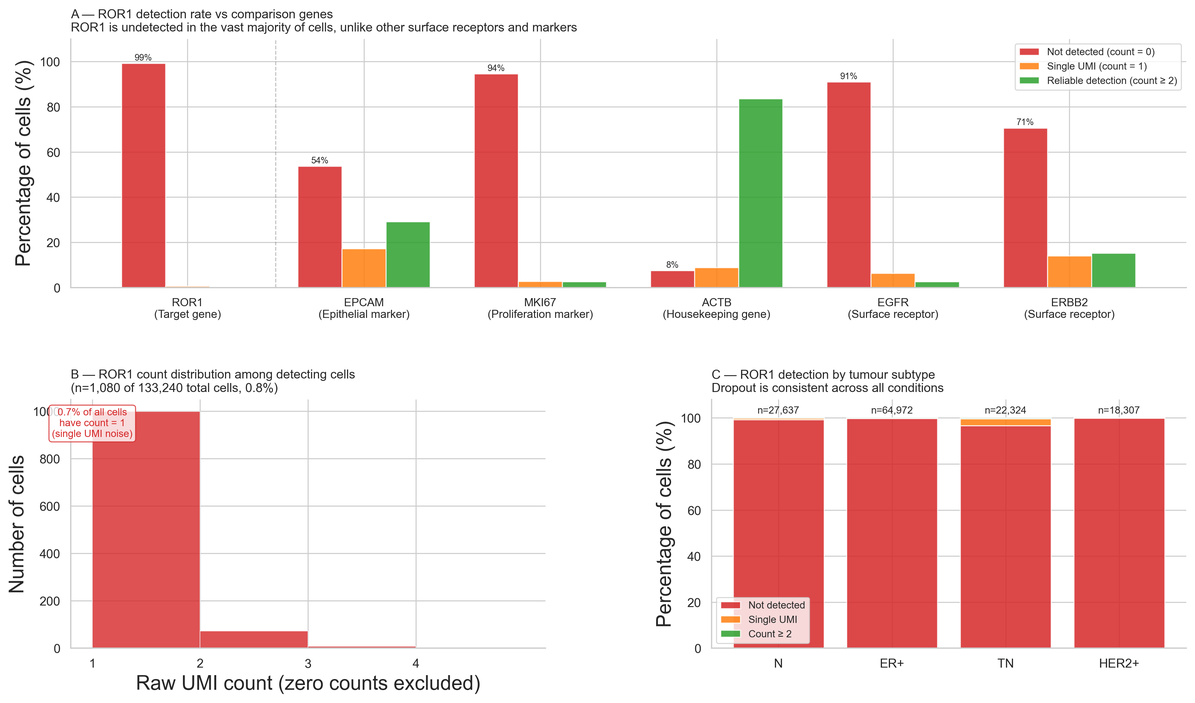

In [17]:
#Transcript Dropout Visualisation
fig = plt.figure(figsize=(16, 14))
gs  = gridspec.GridSpec(3, 2, figure=fig, hspace=0.45, wspace=0.35)

#a) Detection rate bar chart
ax_a = fig.add_subplot(gs[0, :])

x     = np.arange(len(comparison_genes))
width = 0.25
genes = list(comparison_genes.keys())

bars_zero = ax_a.bar(x - width, stats_df.loc[genes, "pct_zero"],
    width, label="Not detected (count = 0)",
    color="#d62728", alpha=0.85)
bars_one = ax_a.bar(x, stats_df.loc[genes, "pct_count1"],
    width, label="Single UMI (count = 1)",
    color="#ff7f0e", alpha=0.85)
bars_two = ax_a.bar(x + width, stats_df.loc[genes, "pct_count2+"],
    width, label="Reliable detection (count ≥ 2)",
    color="#2ca02c", alpha=0.85)

for bar in bars_zero:
    ax_a.text(bar.get_x() + bar.get_width()/2,
              bar.get_height() + 0.5,
              f"{bar.get_height():.0f}%",
              ha="center", va="bottom", fontsize=7)

ax_a.set_xticks(x)
ax_a.set_xticklabels(
    [f"{g}\n({comparison_genes[g].split(' (')[0]})" for g in genes],
    fontsize=9)
ax_a.set_ylabel("Percentage of cells (%)")
ax_a.set_title("A — ROR1 detection rate vs comparison genes\n"
    "ROR1 is undetected in the vast majority of cells, "
    "unlike other surface receptors and markers",
    fontsize=10, loc="left")
ax_a.legend(fontsize=8)
ax_a.set_ylim(0, 110)
ax_a.spines["top"].set_visible(False)
ax_a.spines["right"].set_visible(False)
ax_a.axvline(x=0.5, color="grey", linewidth=0.8,
             linestyle="--", alpha=0.5)

#b) ROR1 raw count distribution histogram
ax_b = fig.add_subplot(gs[1, 0])

ror1_nonzero = ror1_raw[ror1_raw > 0]
ax_b.hist(ror1_nonzero, bins=range(1, int(ror1_raw.max()) + 2), color="#d62728", alpha=0.8, edgecolor="white", linewidth=0.5)
ax_b.set_xlabel("Raw UMI count (zero counts excluded)")
ax_b.set_ylabel("Number of cells")
ax_b.set_title(
    f"B — ROR1 count distribution among detecting cells\n"
    f"(n={len(ror1_nonzero):,} of {len(ror1_raw):,} total cells, "
    f"{len(ror1_nonzero)/len(ror1_raw)*100:.1f}%)",
    fontsize=10, loc="left")
ax_b.set_xticks(range(1, int(ror1_raw.max()) + 1))

pct_count1 = (ror1_raw == 1).mean() * 100
ax_b.text(
    1, ax_b.get_ylim()[1] * 0.85 if ax_b.get_ylim()[1] > 0 else 100,
    f"{pct_count1:.1f}% of all cells\nhave count = 1\n(single UMI noise)",
    ha="center", fontsize=8, color="#d62728",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="#d62728", alpha=0.8))
ax_b.spines["top"].set_visible(False)
ax_b.spines["right"].set_visible(False)

#c) Per-condition ROR1 detection stacked bar
ax_c = fig.add_subplot(gs[1, 1])

conditions = ["N", "ER+", "TN", "HER2+"]
pct_zero_cond, pct_one_cond, pct_two_cond = [], [], []

for condition in conditions:
    mask = tumour.obs["condition"] == condition
    raw  = ror1_raw[mask]
    pct_zero_cond.append((raw == 0).mean() * 100)
    pct_one_cond.append((raw == 1).mean() * 100)
    pct_two_cond.append((raw >= 2).mean() * 100)

x_c = np.arange(len(conditions))
ax_c.bar(x_c, pct_zero_cond,
         label="Not detected", color="#d62728", alpha=0.85)
ax_c.bar(x_c, pct_one_cond, bottom=pct_zero_cond,
         label="Single UMI", color="#ff7f0e", alpha=0.85)
ax_c.bar(x_c, pct_two_cond,
         bottom=[z+o for z,o in zip(pct_zero_cond, pct_one_cond)],
         label="Count ≥ 2", color="#2ca02c", alpha=0.85)

for i, condition in enumerate(conditions):
    n = (tumour.obs["condition"] == condition).sum()
    ax_c.text(i, 102, f"n={n:,}", ha="center", fontsize=8)

ax_c.set_xticks(x_c)
ax_c.set_xticklabels(conditions)
ax_c.set_ylabel("Percentage of cells (%)")
ax_c.set_ylim(0, 108)
ax_c.set_title("C — ROR1 detection by tumour subtype\n"
    "Dropout is consistent across all conditions",
    fontsize=10, loc="left")
ax_c.legend(fontsize=8)
ax_c.spines["top"].set_visible(False)
ax_c.spines["right"].set_visible(False)

plt.savefig(rf"{data_dir}/../Figures/ROR1_Dropout_epi.png", dpi=300, bbox_inches="tight")
plt.show()

In [18]:
#Supplementary statistics table
print("\n=== Summary table for methods/results section ===")
final_table = (stats_df[[
    "pct_detected", "pct_count1", "pct_count2+", "mean_count", "max_count"]]
.rename(columns={
    "pct_detected": "% detected",
    "pct_count1":   "% single UMI",
    "pct_count2+":  "% count ≥2",
    "mean_count":   "mean raw count",
    "max_count":    "max raw count"}))
print(final_table.to_string())
final_table.to_csv("Dataframe_Saves/ROR1_dropout_statistics_N.csv")


=== Summary table for methods/results section ===
       % detected  % single UMI  % count ≥2  mean raw count  max raw count
gene                                                                      
ROR1          0.8           0.7         0.1        0.009000              4
EPCAM        46.3          17.2        29.1        1.766000             66
MKI67         5.5           2.8         2.7        0.134000             60
ACTB         92.5           8.9        83.6       18.127001            626
EGFR          9.0           6.4         2.7        0.147000            132
ERBB2        29.4          14.1        15.3        1.950000            147


ALRA for Dropout-Reconstruction and only on HVGs

In [19]:
%%R
library(ALRA)

In [20]:
import rpy2.robjects as ro
from rpy2.robjects import numpy2ri
from rpy2.robjects.conversion import localconverter

#0 Validating alra_genes against tumour.var_names ───────────────────────
genes_oi_present = [g for g in genes_oi if g in tumour.var_names]
missing            = set(genes_oi) - set(genes_oi_present)

print(f"ALRA genes requested : {len(genes_oi)}")
print(f"ALRA genes in tumour : {len(genes_oi_present)}")
if missing:
    print(f"Missing genes (skipped): {sorted(missing)}")

genes_oi = tumour.var_names[tumour.var["highly_variable"]].tolist()

#1 Initialising accumulator — cells × alra_genes only ───────────────────
X_alra_full = np.zeros((tumour.n_obs, len(genes_oi)), dtype=np.float32)

#2 R memory setup ─────────────────────────────────────────────────────
ro.r('options(mem.maxVSize = Inf)')


ALRA genes requested : 5
ALRA genes in tumour : 5


In [21]:
#3 ALRA loop per sample ───────────────────────────────────────────────
for patient in tumour.obs["sample"].unique():
    mask    = (tumour.obs["sample"] == patient).values
    n_cells = mask.sum()

    if n_cells < 50:
        print(f"Skipping {patient}: only {n_cells} cells")
        continue

    print(f"\nALRA: {patient} ({n_cells:,} cells)")

    # Subset to this sample and alra_genes only
    sub   = tumour[mask, :][:, genes_oi]
    X_sub = sub.X
    if not isinstance(X_sub, np.ndarray):
        X_sub = X_sub.toarray()
    X_sub = X_sub.astype(np.float32)

    print(f"  matrix shape: {X_sub.shape},  "
          f"min={X_sub.min():.2f}, max={X_sub.max():.2f}")

    # Transfer to R
    with localconverter(ro.default_converter + numpy2ri.converter):
        ro.globalenv["X_sub"] = X_sub

    #ALRA internally tries ranks up to k; safe ceiling is min(m,n) - 1,
    #setting k=50 to avoid kernel crash
    k_max = min(n_cells, len(genes_oi)) - 1   #hard ceiling from matrix dims
    k_use = min(50, k_max)                        #practical cap
    ro.globalenv["k_use"] = ro.IntVector([k_use])

    ro.r("""
        result <- alra(X_sub, k = k_use)
        X_imp  <- as.matrix(result[[3]])
    """)

    # Retrieving result
    X_imp = np.array(ro.globalenv["X_imp"], dtype=np.float32)
    assert X_imp.shape == (n_cells, len(genes_oi)), (
        f"Unexpected ALRA output shape {X_imp.shape}, "
        f"expected ({n_cells}, {len(genes_oi)})")

    X_alra_full[mask] = X_imp

    ro.r("rm(X_sub, X_imp, result); gc()")
    gc.collect()
    print(f"  ✅ done")


ALRA: GSM4909253_N-PM0092-Total (3,233 cells)
  matrix shape: (3233, 4506),  min=0.00, max=8.27
Read matrix with 3233 cells and 4506 genes
Getting nonzeros
Randomized SVD
Find the 0.001000 quantile of each gene
Sweep
Scaling all except for 156 columns
0.01% of the values became negative in the scaling process and were set to zero
The matrix went from 25.46% nonzero to 47.60% nonzero
  ✅ done

ALRA: GSM4909254_N-PM0019-Total (4,076 cells)
  matrix shape: (4076, 4506),  min=0.00, max=8.62
Read matrix with 4076 cells and 4506 genes
Getting nonzeros
Randomized SVD
Find the 0.001000 quantile of each gene
Sweep
Scaling all except for 146 columns
0.03% of the values became negative in the scaling process and were set to zero
The matrix went from 27.70% nonzero to 54.12% nonzero
  ✅ done

ALRA: GSM4909257_N-PM0095-Total (1,889 cells)
  matrix shape: (1889, 4506),  min=0.00, max=8.47
Read matrix with 1889 cells and 4506 genes
Getting nonzeros
Randomized SVD
Find the 0.001000 quantile of each g

In [22]:
#4 Storing as a gene-subset layer on a filtered AnnData ─────────────────
# tumour_alra shares the same cells as tumour but only the genes_oi columns
tumour_alra = tumour[:, genes_oi].copy()
tumour_alra.layers["alra"] = sp.csr_matrix(X_alra_full)   #sparse to save RAM

del X_alra_full
gc.collect()

#sanity checks
print(f"\n{'='*60}")
print(f"✅ ALRA complete")
print(f"   tumour_alra shape : {tumour_alra.shape}")
print(f"   layers available  : {list(tumour_alra.layers.keys())}")
print(f"   alra layer dtype  : {tumour_alra.layers['alra'].dtype}")



✅ ALRA complete
   tumour_alra shape : (133240, 4506)
   layers available  : ['counts', 'lognorm', 'alra']
   alra layer dtype  : float32


Save checkpoint

In [23]:
#5 Saving checkpoint ──────────────────────────────────────────
tumour_alra.write("Adata_Saves/tumour_alra.h5ad")
print(f"💾 Saved: tumour_alra.h5ad")

💾 Saved: tumour_alra.h5ad


In [24]:
tumour.uns["genes_oi"] = genes_oi

In [28]:
#6 Plotting Imputed Counts
genes = ["ROR1", "ROR2", "EGFR"]

#Raw values from full tumour object ────────────────────────────────────
raw = tumour[:, genes].X
if not isinstance(raw, np.ndarray):
    raw = raw.toarray()

#ALRA values from tumour_alra ──────────────────────────────────────────
alra_var_names = list(tumour_alra.var_names)   # genes ALRA was run on
alra_index     = {g: i for i, g in enumerate(alra_var_names)}

alra_vals = {}
for g in genes:
    if g in alra_index:
        alra_layer = tumour_alra.layers["alra"]
        col = alra_layer[:, alra_index[g]]
        if hasattr(col, "toarray"):
            col = col.toarray().flatten()
        alra_vals[g] = np.array(col).flatten()
    else:
        print(f"⚠️  {g} not in ALRA gene set — filling with NaN")
        alra_vals[g] = np.full(tumour.n_obs, np.nan)

#Building DataFrame ───────────────────────────────────────────────────────
df = pd.DataFrame({
    "ROR1_raw":  raw[:, 0],
    "ROR2_raw":  raw[:, 1],
    "EGFR_raw":  raw[:, 2],
    "ROR1_alra": alra_vals["ROR1"],
    "ROR2_alra": alra_vals["ROR2"],
    "EGFR_alra": alra_vals["ROR1"]})

In [29]:
print(tumour.var.head())
print(tumour.var_names[:10])

               mt   ribo     hb  n_cells  binomial_deviance  highly_deviant  \
AL627309.1  False  False  False      336         286.110101           False   
AL732372.1  False  False  False      102         235.439377           False   
AC114498.1  False  False  False       21         109.568888           False   
AL669831.5  False  False  False     4266        1554.987156           False   
FAM87B      False  False  False       27          58.082628           False   

            highly_variable  
AL627309.1            False  
AL732372.1            False  
AC114498.1            False  
AL669831.5            False  
FAM87B                False  
Index(['AL627309.1', 'AL732372.1', 'AC114498.1', 'AL669831.5', 'FAM87B',
       'LINC00115', 'FAM41C', 'AL645608.7', 'AL645608.3', 'AL645608.5'],
      dtype='object')


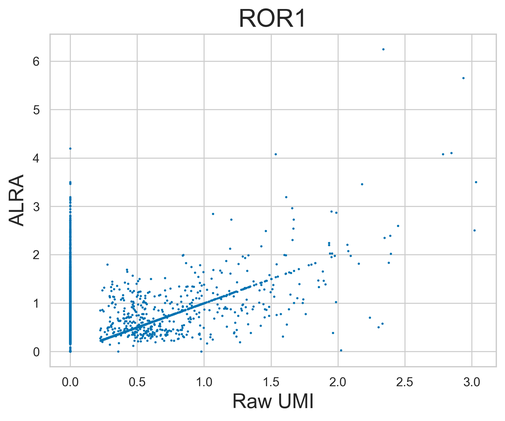

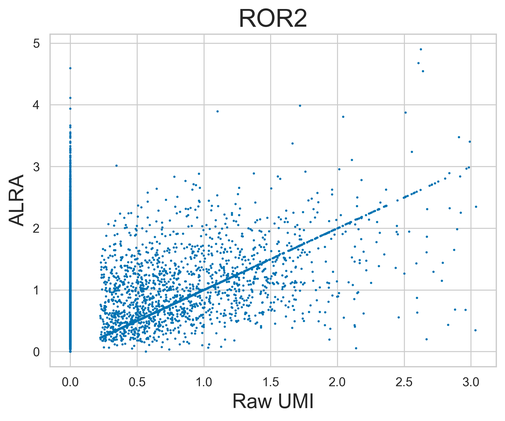

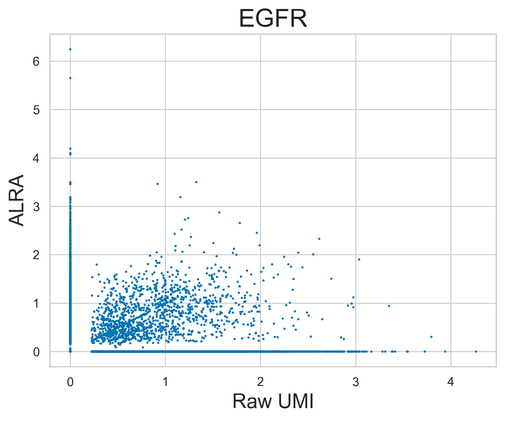

In [30]:
for g in genes:
    plt.figure()
    plt.scatter(df[f"{g}_raw"], df[f"{g}_alra"], s=1)
    plt.xlabel("Raw UMI")
    plt.ylabel("ALRA")
    plt.title(g)

    plt.savefig(rf"{data_dir}/../Figures/ROR1_Dropout_epi.png", dpi=300, bbox_inches="tight")
    plt.show()

STEP6: CNV Scores

In [31]:
#1 Translating genes into chromosome positions
import infercnvpy as cnv
import pybiomart

gtf_file = rf"{data_dir}/../gtf/gencode.v50.chr_patch_hapl_scaff.annotation.gtf"
gtf = pd.read_csv(gtf_file, sep='\t', comment='#', header=None,
                  names=['chr', 'source', 'feature', 'start', 'end', 'score', 'strand', 'frame', 'attribute'])
genes = gtf[gtf['feature'] == 'gene'].copy()
genes['gene_id'] = genes['attribute'].str.extract('gene_id "([^"]+)"')
genes['gene_name'] = genes['attribute'].str.extract('gene_name "([^"]+)"')
genes_unique = (genes[['gene_name', 'chr', 'start', 'end']]
                .dropna(subset=['gene_name'])
                .rename(columns={'chr': 'chromosome'})
                .drop_duplicates(subset='gene_name')
                .set_index('gene_name'))
genes_by_id = (genes[['gene_id', 'chr', 'start', 'end']]
               .rename(columns={'gene_id': 'gene', 'chr': 'chromosome'})
               .drop_duplicates('gene')
               .set_index('gene'))
del gtf
print(f"Gencode genes: {genes_unique.shape[0]}")

/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Gencode genes: 79139


In [32]:
dataset = pybiomart.Dataset(name='hsapiens_gene_ensembl',
                            host='http://www.ensembl.org')
mapping_ext = dataset.query(attributes=[
    'external_gene_name',
    'external_synonym',
    'chromosome_name',
    'start_position',
    'end_position'])
print(mapping_ext.columns.tolist())#to verify col names

gene_col, synonym_col, chr_col, start_col, end_col = mapping_ext.columns[:5]

primary = (mapping_ext[[gene_col, chr_col, start_col, end_col]]
           .drop_duplicates(subset=gene_col)
           .set_index(gene_col)
           .rename(columns={chr_col: 'chromosome', start_col: 'start', end_col: 'end'}))

synonym = (mapping_ext[[synonym_col, chr_col, start_col, end_col]]
           .dropna(subset=[synonym_col])
           .drop_duplicates(subset=synonym_col)
           .set_index(synonym_col)
           .rename(columns={chr_col: 'chromosome', start_col: 'start', end_col: 'end'}))

print(f"Primary symbols:  {len(primary)}")
print(f"Synonym mappings: {len(synonym)}")

tumour.var['chromosome'] = None
tumour.var['start'] = None
tumour.var['end'] = None

for pass_name, ref in [("GTF", genes_unique), ("biomart", primary), ("synonym", synonym)]:
    mask = tumour.var['chromosome'].isna()
    if mask.sum() == 0:
        print(f"All genes resolved before {pass_name} pass — stopping early")
        break
    orig = tumour.var_names[mask]
    clean = pd.Index(orig).str.replace(r'\.\d+$', '', regex=True)
    lk = ref.reindex(clean)
    lk.index = orig
    for col in ['chromosome', 'start', 'end']:
        tumour.var.loc[mask, col] = lk[col]
    print(f"After {pass_name} pass: {tumour.var['chromosome'].isna().sum()} missing")

final_missing = tumour.var_names[tumour.var['chromosome'].isna()].tolist()
print(f"\nDropping {len(final_missing)} truly unresolvable genes")
print(f"Sample: {final_missing[:20]}")


['Gene name', 'Gene Synonym', 'Chromosome/scaffold name', 'Gene start (bp)', 'Gene end (bp)']
Primary symbols:  41452
Synonym mappings: 55748
After GTF pass: 5349 missing
After biomart pass: 5302 missing
After synonym pass: 4723 missing

Dropping 4723 truly unresolvable genes
Sample: ['AL627309.1', 'AL732372.1', 'AC114498.1', 'AL669831.5', 'AL645608.7', 'AL645608.3', 'AL645608.5', 'AL645608.1', 'AL645608.8', 'AL645608.2', 'AL645608.9', 'AL390719.2', 'AL162741.1', 'AL391244.3', 'AL645728.1', 'AL691432.2', 'FO704657.1', 'AL109917.1', 'AL391845.2', 'AL391845.1']


In [33]:
#keeping only resolved genes
mask = tumour.var['chromosome'].notna()
tumour = tumour[:, mask].copy()

#keeping only autosomes
valid_chr = [f"chr{i}" for i in range(1, 23)] + [str(i) for i in range(1, 23)]
chr_mask = tumour.var["chromosome"].isin(valid_chr)
print(f"Keeping {chr_mask.sum()} autosomal genes")

tumour = tumour[:, chr_mask].copy()

#removing problematic genes BEFORE inferCNV
bad_exact = ["MALAT1", "NEAT1"]

bad_gene_mask = (
        tumour.var_names.str.startswith(
            ("MT-", "RPS", "RPL", "HLA-", "IGH", "IGK", "IGL", "KRT", "SPRR", "S100A"))|
        tumour.var_names.isin(bad_exact))
print(f"Removing {bad_gene_mask.sum()} problematic genes")
tumour = tumour[:, ~bad_gene_mask].copy()

#removing sparse genes
sc.pp.filter_genes(tumour, min_cells=100)
print(f"Remaining genes: {tumour.n_vars}")

#sorting genes genomically
tumour.var["chromosome"] = tumour.var["chromosome"].astype(str)

tumour.var["chr_num"] = (tumour.var["chromosome"]
                         .str.replace("chr", "", regex=False)
                         .astype(int))

tumour.var = tumour.var.sort_values(["chr_num", "start"])
tumour = tumour[:, tumour.var.index].copy()
print("Genes sorted by genomic position")

#ensuring raw counts
tumour.X = tumour.layers["counts"].copy()

import scipy.sparse as sp

Keeping 17943 autosomal genes
Removing 264 problematic genes
Remaining genes: 15908
Genes sorted by genomic position


In [34]:
#2  Defining a Global healthy epithelial reference
ref_mask = tumour.obs["condition"] == "N"
reference = tumour[ref_mask].copy()
reference.X = reference.layers["counts"].copy()

if not sp.issparse(reference.X):
    reference.X = sp.csr_matrix(reference.X)

gc.collect()

print(f"Reference epithelial cells: {reference.n_obs}")
print(f"Normal donors: {reference.obs['sample'].nunique()}")

Reference epithelial cells: 27637
Normal donors: 13


In [35]:
#3 Run inferCNV
# Prepare output containers
tumour.obs["cnv_score"] = np.nan
tumour.obs["cnv_signal"] = np.nan

X_cnv_full = None  # plain variable, NOT stored in adata.obsm yet

tumor_global_refs = reference.copy()
tumor_global_refs.obs["cnv_reference"] = "reference"

for sample in tumour.obs["sample"].unique():
    print(f"\nProcessing {sample}")
    target = global_refs = ad_sub = None
    try:
        target = tumour[tumour.obs["sample"] == sample].copy()
        target.X = target.layers["counts"].copy()
        if not sp.issparse(target.X):
            target.X = sp.csr_matrix(target.X)

        if target.obs["condition"].iloc[0] == "N":
            global_refs = reference[reference.obs["sample"] != sample].copy()
            global_refs.obs["cnv_reference"] = "reference"
        else:
            global_refs = tumor_global_refs

        target.obs["cnv_reference"] = "query"

        ad_sub = sc.concat([global_refs, target], join="inner", merge="same")
        ad_sub.X = ad_sub.layers["counts"].copy()

        cnv.tl.infercnv(ad_sub,
            reference_key="cnv_reference", reference_cat=["reference"], window_size=100, step=10, dynamic_threshold=0.5, exclude_chromosomes=("chrX", "chrY"), n_jobs=1)

        if "cnv" not in tumour.uns:
            tumour.uns["cnv"] = ad_sub.uns["cnv"].copy()
        X_cnv = ad_sub.obsm["X_cnv"]

        if sp.issparse(X_cnv):
            X_cnv = X_cnv.toarray()
        target_mask = ad_sub.obs["cnv_reference"] == "query"
        target_names = ad_sub.obs_names[target_mask]
        X_target = X_cnv[target_mask]

        #Calcultes Chromosome-level burden
        chr_pos_dict = ad_sub.uns["cnv"]["chr_pos"]  # {chrom: start_window_idx}
        sorted_items = sorted(chr_pos_dict.items(), key=lambda x: x[1])

        n_windows = X_cnv.shape[1]
        chr_labels_arr = np.empty(n_windows, dtype=object)

        for i, (chrom, start) in enumerate(sorted_items):
            end = sorted_items[i + 1][1] if i + 1 < len(sorted_items) else n_windows
            chr_labels_arr[start:end] = chrom

        chr_labels = pd.Series(chr_labels_arr)

        chromosome_scores = []

        for chrom in chr_labels.unique():
            idx = np.where(chr_labels.values == chrom)[0]
            chr_score = np.sqrt(
                np.mean(X_target[:, idx] ** 2, axis=1,))
            chromosome_scores.append(chr_score)

        chromosome_scores = np.column_stack(chromosome_scores)

        weights = np.array([np.sum(chr_labels.values == chrom)
            for chrom in chr_labels.unique()])

        weights = weights / weights.sum()

        cnv_score = np.average(chromosome_scores, axis=1, weights=weights)
        cnv_signal = np.max(np.abs(X_target), axis=1)

        #writing scores back into adata.obs
        tumour.obs.loc[target_names, "cnv_score"] = cnv_score
        tumour.obs.loc[target_names, "cnv_signal"] = cnv_signal

        #lazy-allocate the real array
        if X_cnv_full is None:
            X_cnv_full = np.zeros((tumour.n_obs, X_target.shape[1]), dtype=np.float32)

        idx = tumour.obs_names.get_indexer(target_names)
        X_cnv_full[idx] = X_target

        print("Success")
        print(pd.Series(cnv_score).describe())

    except Exception as e:
        print(f"Failed on {sample}")
        print(e)
    finally:
        del target
        del global_refs
        del ad_sub
        gc.collect()



Processing GSM4909253_N-PM0092-Total


python3.11(70107) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python3.11(70108) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
100%|██████████| 6/6 [00:23<00:00,  3.94s/it]


Success
count    3233.000000
mean        0.065472
std         0.015536
min         0.047098
25%         0.055510
50%         0.058649
75%         0.070083
max         0.141718
dtype: float64

Processing GSM4909254_N-PM0019-Total


python3.11(70174) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
100%|██████████| 6/6 [00:25<00:00,  4.28s/it]


Success
count    4076.000000
mean        0.065480
std         0.014095
min         0.047192
25%         0.056565
50%         0.060420
75%         0.068993
max         0.145196
dtype: float64

Processing GSM4909257_N-PM0095-Total


...

Success
count    3424.000000
mean        0.061119
std         0.006320
min         0.050496
25%         0.057917
50%         0.059474
75%         0.061726
max         0.112443
dtype: float64

Processing GSM4909315_ER-MH0167-T


python3.11(70717) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
100%|██████████| 7/7 [00:18<00:00,  2.63s/it]


Success
count    4867.000000
mean        0.096089
std         0.037406
min         0.047495
25%         0.057054
50%         0.093726
75%         0.122216
max         0.218604
dtype: float64

Processing GSM4909317_ER-MH0173-T


python3.11(70721) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
100%|██████████| 7/7 [00:16<00:00,  2.35s/it]


Success
count    2866.000000
mean        0.099288
std         0.036662
min         0.049395
25%         0.064636
50%         0.095258
75%         0.122822
max         0.212871
dtype: float64


In [36]:
#Only now attaching the finished, fully-shaped array to obsm
if X_cnv_full is not None:
    tumour.obsm["X_cnv"] = X_cnv_full
else:
    print("Warning: no samples produced CNV results — X_cnv not set")

print(tumour.obs["cnv_score"].isna().sum())  #should be only reference cells
print(tumour.obs["cnv_score"].describe())  #should show non-zero variance
#7 UMAP coloured by CNV Score#Step takes 40min

0
count    133240.000000
mean          0.076078
std           0.027553
min           0.044750
25%           0.057341
50%           0.064046
75%           0.085527
max           0.251285
Name: cnv_score, dtype: float64


STEP 7: Integration

In [37]:
import scvi
from scvi import model
#subset to HVGs and set up scVI with RAW counts
tumour_scvi = tumour[:, tumour.var["highly_variable"]].copy()
#Ensure counts are raw integers
x = tumour_scvi.layers["counts"][:5, :5]
print("\nRaw count check (expect integers):")
print(x.toarray() if hasattr(x, "toarray") else x)
gc.collect()


Raw count check (expect integers):
[[0. 1. 0. 1. 0.]
 [0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 1.]
 [0. 1. 0. 1. 1.]
 [0. 0. 0. 1. 0.]]


222

In [38]:
#Setup and train scVI
scvi.model.SCVI.setup_anndata(tumour_scvi, layer="counts", batch_key="sample")
model = scvi.model.SCVI(tumour_scvi, n_latent=20, n_layers=2, gene_likelihood="zinb")
model.train(accelerator="mps", early_stopping=True, early_stopping_patience=20)#takes 33min

/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch/Jax operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and tr

Epoch 60/60: 100%|██████████| 60/60 [18:24<00:00, 18.26s/it, v_num=1, train_loss=1.48e+3]

`Trainer.fit` stopped: `max_epochs=60` reached.


Epoch 60/60: 100%|██████████| 60/60 [18:24<00:00, 18.40s/it, v_num=1, train_loss=1.48e+3]


In [39]:
#Storing latent representation
tumour.obsm["X_scVI"] = model.get_latent_representation(tumour_scvi)
model.save("scvi_tumour_model/", overwrite=True)
del model, tumour_scvi
gc.collect()

2318

STEP 8: Leiden Clustering

In [40]:
sc.pp.neighbors(tumour, use_rep="X_scVI", n_neighbors=30)
sc.tl.leiden(tumour, key_added="tum_scVI_leiden", resolution=0.5)
sc.tl.umap(tumour)

/var/folders/kn/dz8n2v_j7cq3qn3h60y7qmwh0000gp/T/ipykernel_68214/3498857967.py:2: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(tumour, key_added="tum_scVI_leiden", resolution=0.5)


In [41]:
genes_oi = tumour.uns["genes_oi"]
alra_index = {g: i for i, g in enumerate(genes_oi)}

In [42]:
#Building index from tumour_alra.var_names ────────────────────────────────
alra_index = {g: i for i, g in enumerate(tumour_alra.var_names)}

#Extracting full ALRA matrix from layer ───────────────────────────────────
X_alra_full = tumour_alra.layers["alra"]
if hasattr(X_alra_full, "toarray"):
    X_alra_full = X_alra_full.toarray()

#Storing in tumour.obsm so it's saved with tumour ────────────────────────
tumour.obsm["X_alra"] = X_alra_full   # shape: (n_cells, n_alra_genes)

#Storing per-gene ALRA values in tumour.obs ──────────────────────────────
for gene in ["ROR1", "ROR2", "EGFR"]:
    if gene in alra_index:
        tumour.obs[f"{gene}_alra"] = X_alra_full[:, alra_index[gene]]
    else:
        print(f"⚠️  {gene} not in ALRA gene set — skipping")

#Clean up ──────────────────────────────────────────────────────────────
del X_alra_full
gc.collect()

97243

In [43]:
tumour.obs["sample_short"] = (tumour.obs["sample"]
    .str.split("_", n=1).str[1]      # TN-B1-MH4031
    .str.replace(r"^(N)-", "", regex=True)
    .astype("category"))

Plottiing UMAPs

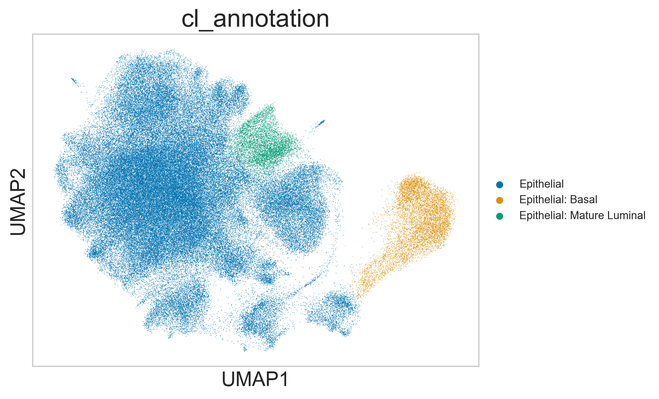

In [44]:
tumour.obs["cl_annotation"] = tumour.obs["cl_annotation"].astype("category")

sc.pl.umap(tumour,color=["cl_annotation"], ncols=1, vmax="p99", show=False)

plt.savefig(rf"{data_dir}/../Figures/cl_annotation_N_epi.png", dpi=300, bbox_inches="tight")
plt.show()

In [45]:
condition_palette = {"HER2": "#2CA02C", "HER2+": "#2CA02C", "TN": "#976391", "ER": "#F46036", "ER+": "#F46036", "N": "#031A6B"}

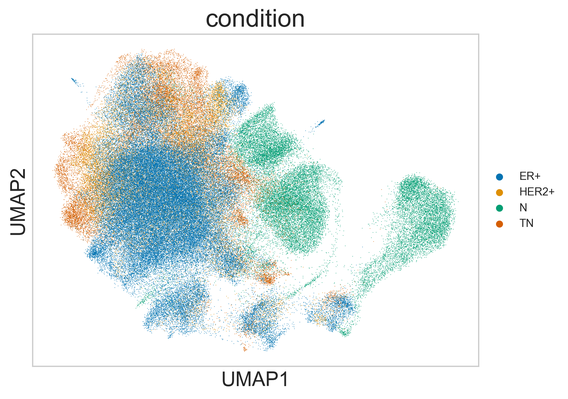

In [46]:
tumour.obs["condtion"] = tumour.obs["condition"].astype("category")

sc.pl.umap(tumour,color=["condition"], ncols=1, vmax="p99", show=False)

plt.savefig(rf"{data_dir}/../Figures/condition_N_epi.png", dpi=300, bbox_inches="tight")
plt.show()

In [47]:
# Print number of cells per annotation
print(tumour.obs["cl_annotation"].value_counts())

cl_annotation
Epithelial                    118618
Epithelial: Basal               8048
Epithelial: Mature Luminal      6574
Name: count, dtype: int64


In [48]:
condition_order = ["TN", "HER2+", "ER+", "N"]
tumour.obs["condition"] = pd.Categorical(tumour.obs["condition"], categories=condition_order, ordered=True)

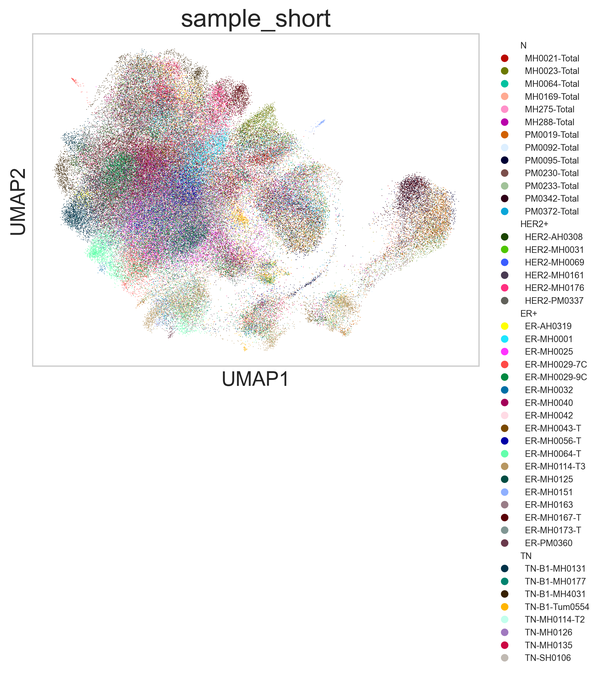

In [49]:
from matplotlib.lines import Line2D
#Plot UMAP without default legend ───────────────────────────────
sc.pl.umap(tumour, color="sample_short", legend_loc=None, show=False)
ax = plt.gca()

#Extract colours assigned by Scanpy ─────────────────────────────
samples = tumour.obs["sample_short"].cat.categories
colors  = tumour.uns["sample_short_colors"]
sample_to_color = dict(zip(samples, colors))

#Build grouped legend ───────────────────────────────────────────
handles = []

for condition in ["N", "HER2+", "ER+", "TN"]:
    # header (invisible marker)
    handles.append(Line2D([], [], linestyle="none", label=f"{condition}", color="black"))
    # samples belonging to this condition
    cond_samples = (tumour.obs.loc[tumour.obs["condition"] == condition, "sample_short"].unique())

    for sample in sorted(cond_samples):
        handles.append(Line2D([], [], marker="o", linestyle="none", markersize=6, markerfacecolor=sample_to_color[sample], markeredgecolor="none", label=f"  {sample}"))

#Draw legend ────────────────────────────────────────────────────
ax.legend(handles=handles, bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False, fontsize=7)
plt.savefig(rf"{data_dir}/../Figures/Sample_N_epi.png", dpi=300, bbox_inches="tight")
plt.show()

Saving Checkpoint for Progress

In [50]:
#1 Sanity check what actually exists
expected = {
    "obs": ["condition", "sample", "sample_short", "cl_annotation",
            "cnv_score", "cnv_signal", "tum_scVI_leiden", "ROR1_alra", "ROR2_alra", "EGFR_alra"],
    "obsm": ["X_scVI", "X_umap", "X_cnv", "X_alra"],
    "uns": ["alra_genes", "cnv"],
    "var": ["highly_variable", "highly_deviant", "binomial_deviance",
            "chromosome", "start", "end", "chr_num"]}
stores = {"obs": tumour.obs, "obsm": tumour.obsm, "uns": tumour.uns, "var": tumour.var}

for label, keys in expected.items():
    missing = [k for k in keys if k not in stores[label]]
    if missing:
        print(f"⚠️  Missing from tumour.{label}: {missing}")

if not sp.issparse(tumour.layers["lognorm"]):
    tumour.layers["lognorm"] = sp.csr_matrix(tumour.layers["lognorm"])

def sanitize_for_h5ad(df, label=""):
    """Object-dtype columns crash h5ad writes if they contain non-string
    values (ints, floats, None mixed in). Convert each to a clean numeric
    or categorical dtype so write_h5ad never has to guess."""
    for col in df.columns:
        if df[col].dtype == object:
            n_before = df[col].notna().sum()
            coerced = pd.to_numeric(df[col], errors="coerce")
            if coerced.notna().sum() == n_before:
                #every non-null value converted
                df[col] = coerced
                print(f"  {label}.{col}: object -> numeric")
            else:
                #not numeric -> categorical
                df[col] = df[col].astype(str).where(df[col].notna(), np.nan)
                df[col] = df[col].astype("category")
                print(f"  {label}.{col}: object -> category")
    return df

print("Sanitizing dtypes before write:")
tumour.obs = sanitize_for_h5ad(tumour.obs, "obs")
tumour.var = sanitize_for_h5ad(tumour.var, "var")
#2 Cast everything sparse-able to sparse before writing to save memory
if not sp.issparse(tumour.X):
    tumour.X = sp.csr_matrix(tumour.X)

for lname in list(tumour.layers.keys()):
    if not sp.issparse(tumour.layers[lname]):
        tumour.layers[lname] = sp.csr_matrix(tumour.layers[lname])

⚠️  Missing from tumour.uns: ['alra_genes']
Sanitizing dtypes before write:
  var.start: object -> numeric
  var.end: object -> numeric


In [51]:
#3 Atomic write: write to a temp file, then rename
out_dir = f"{data_dir}/../h5ad_saves"
os.makedirs(out_dir, exist_ok=True)
out_path = f"{out_dir}/tumour_full.h5ad"
tmp_path = out_path + ".tmp"

tumour.write_h5ad(tmp_path, compression="gzip")
os.replace(tmp_path, out_path)  #atomic on the same filesystem

print(f"💾 Saved: {out_path}")
print(tumour)
print("\nobs columns:", list(tumour.obs.columns))
print("layers:     ", list(tumour.layers.keys()))
print("obsm keys:  ", list(tumour.obsm.keys()))
print("uns keys:   ", list(tumour.uns.keys()))
gc.collect()

💾 Saved: /Volumes/TOSHIBA EXT/Nowotny/ENV1/head/../h5ad_saves/tumour_full.h5ad
AnnData object with n_obs × n_vars = 133240 × 15908
    obs: 'sample', 'condition', 'total_counts', 'n_genes_by_counts', 'scVI_leiden', 'cl_annotation', 'cnv_score', 'cnv_signal', 'tum_scVI_leiden', 'ROR1_alra', 'ROR2_alra', 'EGFR_alra', 'sample_short', 'condtion'
    var: 'mt', 'ribo', 'hb', 'n_cells', 'binomial_deviance', 'highly_deviant', 'highly_variable', 'chromosome', 'start', 'end', 'chr_num'
    uns: 'log1p', 'genes_oi', 'cnv', 'neighbors', 'tum_scVI_leiden', 'umap', 'cl_annotation_colors', 'condition_colors', 'sample_short_colors'
    obsm: 'X_cnv', 'X_scVI', 'X_umap', 'X_alra'
    layers: 'counts', 'lognorm'
    obsp: 'distances', 'connectivities'

obs columns: ['sample', 'condition', 'total_counts', 'n_genes_by_counts', 'scVI_leiden', 'cl_annotation', 'cnv_score', 'cnv_signal', 'tum_scVI_leiden', 'ROR1_alra', 'ROR2_alra', 'EGFR_alra', 'sample_short', 'condtion']
layers:      ['counts', 'lognorm']


35

In [ ]:
Deliberate Break -> Restart Kernel to save RAM

Figure Parameters

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="paper", palette="colorblind")
plt.rcParams.update({"font.size": 20, "axes.titlesize": 20, "axes.labelsize": 16, "xtick.labelsize": 10, "ytick.labelsize": 10})
plt.rcParams["figure.dpi"] = 300

#loading files
data_dir = "/Volumes/TOSHIBA EXT/Nowotny/ENV1/head"

condition_palette = {"HER2": "#2CA02C", "HER2+": "#2CA02C", "TN": "#976391", "ER": "#F46036", "ER+": "#F46036", "N": "#031A6B"}

celltype_palette = {
    #immune compartments
    "T Cells": "#2166AC",#deep blue
    "B Cells": "#FFD92F",#bright yellow
    "Plasma Cells": "#FF7F00",#orange
    "Macrophages": "#33A02C",#green
    "Mast Cells": "#8C510A",#brown
    "Dendritic": "#6A3D9A",#violet-purple

    #stromal compartments
    "Fibroblasts": "#D73027",#red
    "Endothelial": "#F781BF",#pink

    #epithelial compartments
    "Epithelial": "#00BFC4",#turquoise
    "Epithelial: Luminal Progenitor": "#A6CEE3",#light cyan
    "Epithelial: Mature Luminal": "#1F9E89",#teal
    "Epithelial: Basal": "#00441B",#dark green-teal

    # fallback
    "Unknown": "#808080"#grey
}

Importing Libraries

In [2]:
import os
import scanpy as sc
import pandas as pd
import numpy as np
import gseapy as gp
import gc
import scipy.sparse as sp
import psutil
import anndata as ad

Loading Adata

In [3]:
tumour = sc.read_h5ad(rf"{data_dir}/../h5ad_saves/tumour_full.h5ad")
print(f"Available RAM: {psutil.virtual_memory().available / 1e9:.1f} GB")

Available RAM: 1.3 GB


Checking Plots

/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


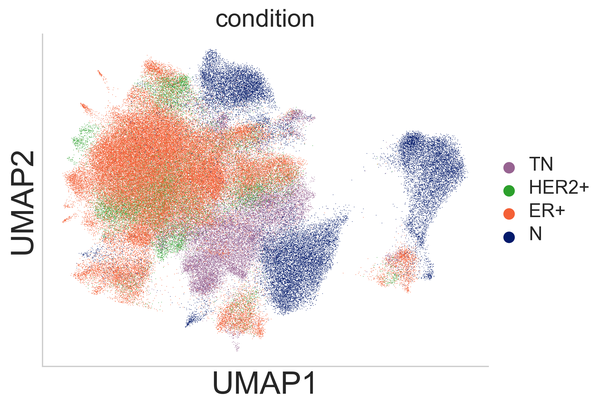

In [4]:
# Desired visual layering:
# HER2+ drawn first (bottom)
# TN drawn second
# ER+ drawn last (top)
plot_order = ["TN", "HER2", "ER+"]
# Keep N separate / draw it first as the bottom layer
plot_order = ["N", "TN", "HER2+", "ER+"]

# Create plotting order
condition_rank = {condition: i
    for i, condition in enumerate(plot_order)}

plot_idx = (tumour.obs["condition"].map(condition_rank).sort_values().index)
# Plot reordered cells
sc.pl.umap(tumour[plot_idx],
    color="condition", palette=condition_palette, ncols=1, vmax="p99", show=False)
ax = plt.gca()

# Remove top and right spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Keep left and bottom spines
ax.spines["left"].set_visible(True)
ax.spines["bottom"].set_visible(True)

# Axis labels
ax.set_xlabel("UMAP1", fontsize=25)
ax.set_ylabel("UMAP2", fontsize=25)

# Tick labels
ax.tick_params(axis="both", labelsize=12)

# Legend
legend = ax.get_legend()

if legend is not None:
    plt.setp(legend.get_texts(), fontsize=15)

    # Larger legend markers
    for handle in legend.legend_handles:
        handle.set_sizes([70])

plt.savefig(rf"{data_dir}/../Figures/umap_condition.png", dpi=300, bbox_inches="tight")
plt.show()

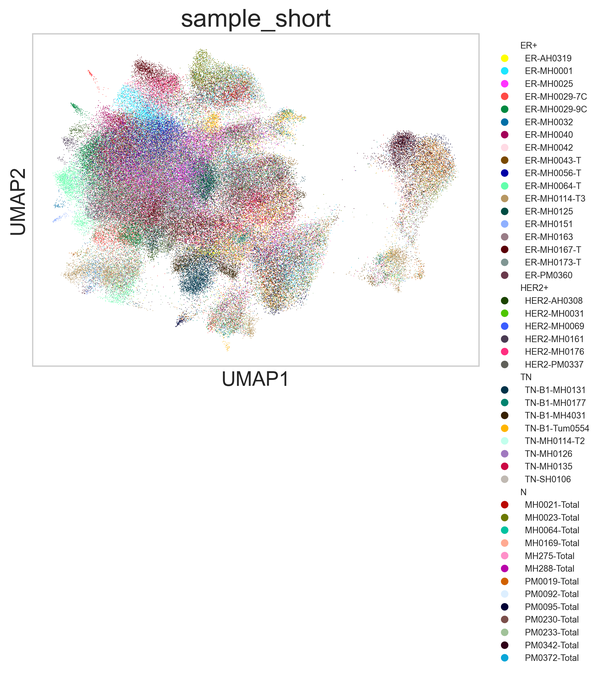

In [5]:
from matplotlib.lines import Line2D
#3 UMAP coloured by sample with short sample names
#plotting UMAP without default legend
sc.pl.umap(tumour, color="sample_short", legend_loc=None,show=False)
ax = plt.gca()

#extract colours assigned by Scanpy
samples = tumour.obs["sample_short"].cat.categories
colors  = tumour.uns["sample_short_colors"]

sample_to_color = dict(zip(samples, colors))

#building grouped legend
handles = []

for condition in ["ER+", "HER2+", "TN", "N"]:
    #header (invisible marker)
    handles.append(Line2D([], [], linestyle="none", label=f"{condition}",color="black"))

    #samples belonging to this condition
    cond_samples = (tumour.obs.loc[tumour.obs["condition"] == condition, "sample_short"].unique())

    for sample in sorted(cond_samples):
        handles.append(Line2D([], [], marker="o", linestyle="none", markersize=6,markerfacecolor=sample_to_color[sample], markeredgecolor="none", label=f"  {sample}"))

#drawing legend
ax.legend(handles=handles, bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False, fontsize=7)

plt.savefig(rf"{data_dir}/../Figures/3_All_Sample.png", dpi=300, bbox_inches="tight")
plt.show()

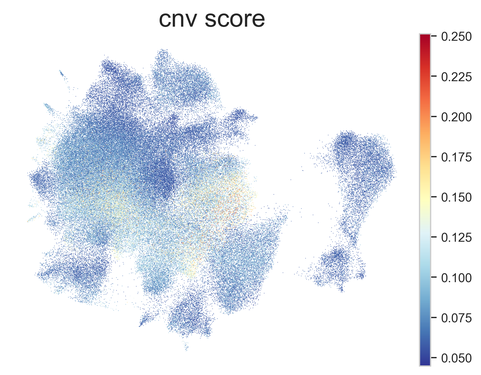

In [6]:
sc.pl.umap(tumour, color="cnv_score", legend_loc="right margin", legend_fontsize=8, title="cnv score", cmap="RdYlBu_r", frameon=False, show=False)
plt.savefig(rf"{data_dir}/../Figures/cnv_N_epi.png", dpi=300, bbox_inches="tight")

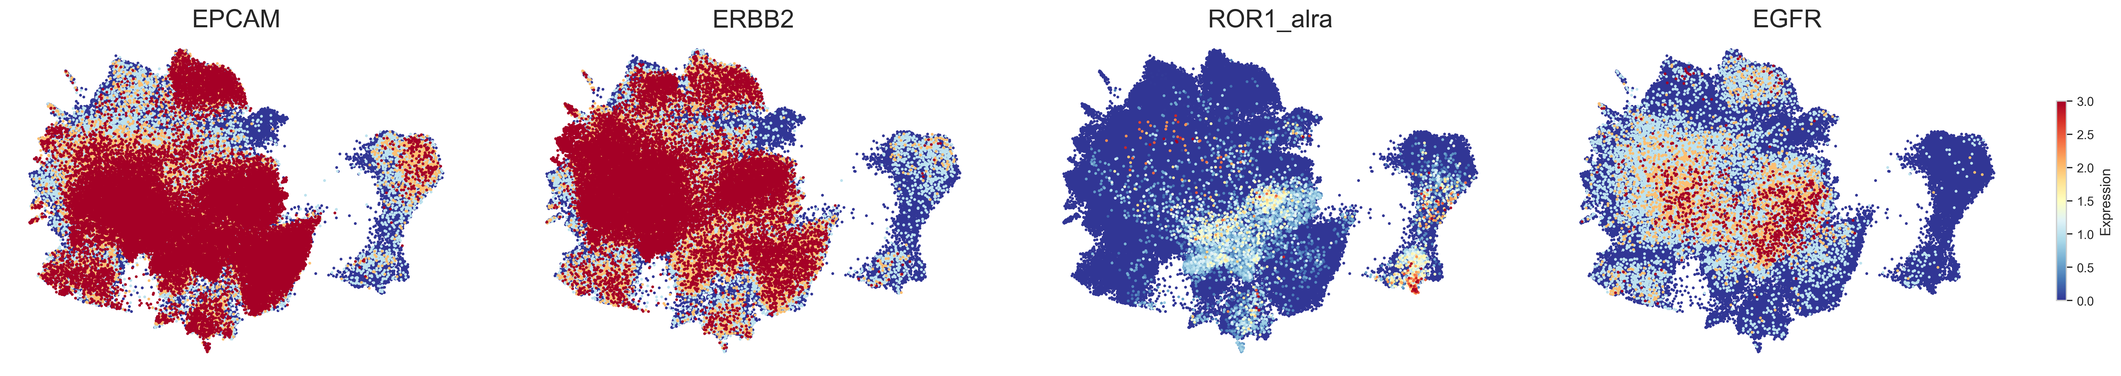

In [7]:
features = ["EPCAM", "ERBB2", "ROR1_alra", "EGFR"]

#Helper function
def get_values(adata, key):
    if key in adata.var_names:
        return adata[:, key].X.toarray().flatten()
    else:
        return adata.obs[key].values

cmap = "RdYlBu_r"
vmin, vmax = 0, 3

axes = sc.pl.umap(tumour, color=features, ncols=4, cmap=cmap, vmax=vmax, vmin=vmin, size=20, frameon=False, show=False,
                  colorbar_loc=None)#← suppress individual colorbars

fig = plt.gcf()
# Add a single shared colorbar on the right
norm = plt.Normalize(vmin=vmin, vmax=vmax)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=fig.axes, orientation="vertical", fraction=0.02, pad=0.02, shrink=0.6)
cbar.set_label("Expression", fontsize=11)

plt.savefig(rf"{data_dir}/../Figures/ALRA-counts_N_epi.png", dpi=300, bbox_inches="tight")
plt.show()

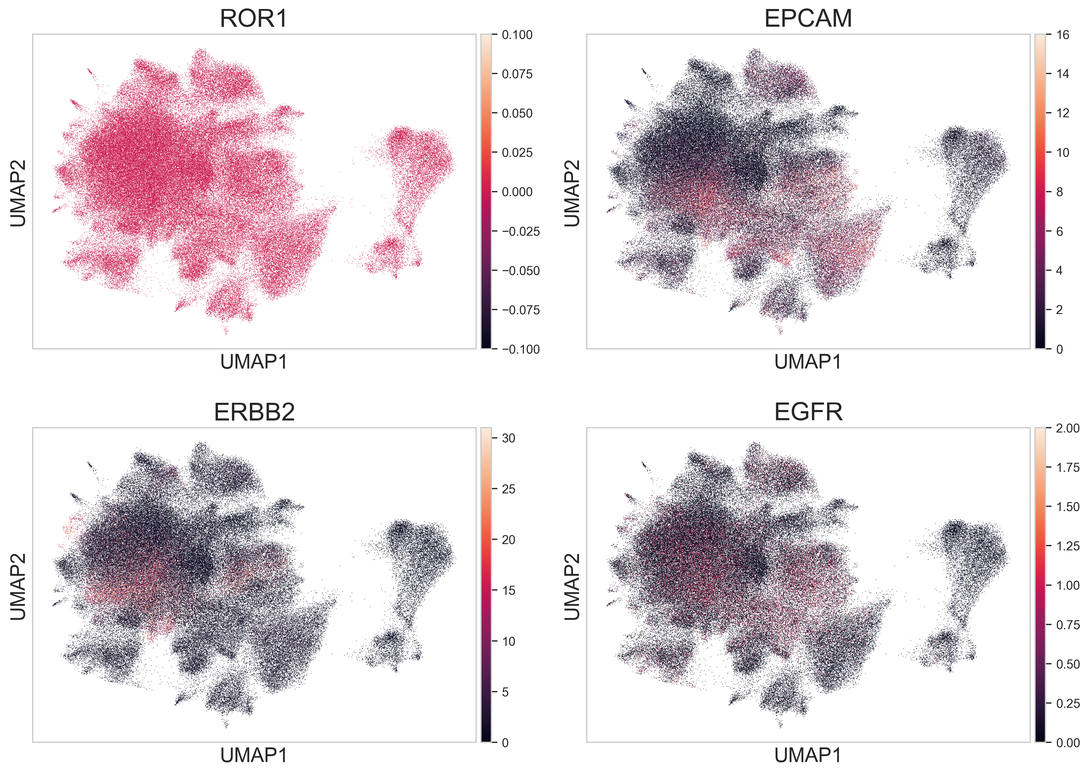

In [8]:
#Raw Distribution to compare
sc.pl.umap(tumour, color=["ROR1", "EPCAM", "ERBB2", "EGFR"], ncols=2, vmax="p99", show=False)

plt.savefig(rf"{data_dir}/../Figures/RAW-counts_N_epi.png", dpi=300, bbox_inches="tight")
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

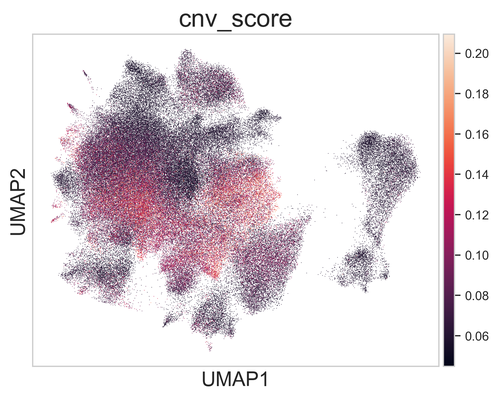

In [9]:
sc.pl.umap(tumour, color="cnv_score", vmax="p99.9", show=False)
plt.savefig(rf"{data_dir}/../Figures/9_cnv_score.png", dpi=300, bbox_inches="tight")
plt.show

Testing Different Leiden Resolutions

In [10]:
sc.tl.leiden(tumour, resolution=1.0, key_added="tum_scVI_leiden_r1")
sc.tl.leiden(tumour, resolution=1.2, key_added="tum_scVI_leiden_r12")
sc.tl.leiden(tumour, resolution=1.5, key_added="tum_scVI_leiden_r15")

print(f"Resolution 0.5: {tumour.obs['tum_scVI_leiden'].nunique()} clusters")
print(f"Resolution 1.0: {tumour.obs['tum_scVI_leiden_r1'].nunique()} clusters")
print(tumour.obs["tum_scVI_leiden_r12"].value_counts().sort_index())
print(f"Resolution 1.0: {tumour.obs['tum_scVI_leiden_r12'].nunique()} clusters")
print(tumour.obs["tum_scVI_leiden_r15"].value_counts().sort_index())
print(f"Resolution 1.0: {tumour.obs['tum_scVI_leiden_r15'].nunique()} clusters")
print(tumour.obs["tum_scVI_leiden_r1"].value_counts().sort_index())

/var/folders/kn/dz8n2v_j7cq3qn3h60y7qmwh0000gp/T/ipykernel_67537/2653939825.py:1: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(tumour, resolution=1.0, key_added="tum_scVI_leiden_r1")


Resolution 0.5: 18 clusters
Resolution 1.0: 20 clusters
tum_scVI_leiden_r12
0     12599
1     11201
2     10454
3      9881
4      9579
5      9425
6      7546
7      7543
8      7407
9      6937
10     6671
11     5587
12     5536
13     5081
14     4822
15     3374
16     3089
17     2687
18     2362
19      884
20      324
21      179
22       72
Name: count, dtype: int64
Resolution 1.0: 23 clusters
tum_scVI_leiden_r15
0     11109
1      9707
2      8520
3      7641
4      7386
5      7139
6      6912
7      6710
8      6640
9      5525
10     5053
11     5011
12     4982
13     4691
14     4629
15     4589
16     4249
17     4125
18     3375
19     3233
20     3101
21     2854
22     2434
23     1202
24      921
25      844
26      322
27      177
28       84
29       75
Name: count, dtype: int64
Resolution 1.0: 30 clusters
tum_scVI_leiden_r1
0     23268
1     14545
2     12781
3     11426
4     10778
5     10256
6      9001
7      7363
8      6743
9      6673
10     6267
11     50

Step 9: Assingning Gavish Cellstates

In [11]:
#Gavish et al. (2023) malignant cell state annotation
#1 Load Gavish Meta-Program signatures
gavish_file = rf"{data_dir}/../gtf/Gavish_cell_state_signature.xlsx"
gavish_df = pd.read_excel(gavish_file, sheet_name="Cancer MPs")

gavish_states = {
    state: gavish_df[state].dropna().astype(str).tolist()
    for state in gavish_df.columns}

for state, genes in gavish_states.items():
    print(state, len(genes), genes[:5])

MP1  Cell Cycle - G2/M 50 ['TOP2A', 'UBE2C', 'HMGB2', 'NUSAP1', 'CENPF']
MP2  Cell Cycle - G1/S 50 ['PCNA', 'RRM2', 'FEN1', 'GINS2', 'TYMS']
MP3  Cell Cylce HMG-rich 50 ['STMN1', 'TUBA1B', 'H2AFZ', 'DUT', 'TUBB']
MP4  Chromatin  50 ['MT-ND6', 'DST', 'SMARCA5', 'SPEN', 'PCM1']
MP5 Stress  50 ['ATF3', 'EGR1', 'FOS', 'PPP1R15A', 'JUN']
MP6 Hypoxia 50 ['NDRG1', 'BNIP3', 'SLC2A1', 'P4HA1', 'VEGFA']
MP7 Stress (in vitro) 50 ['DDIT3', 'SLC3A2', 'TRIB3', 'ASNS', 'HERPUD1']
MP8 Proteasomal degradation 50 ['PSMA3', 'PSMC4', 'MDH1', 'PRDX1', 'PSMA4']
MP9 Unfolded protein response 50 ['PDIA3', 'MANF', 'PDIA4', 'CRELD2', 'HSPA5']
MP10 Protein maturation 50 ['RPN2', 'PDIA3', 'ATP6AP2', 'HSPA5', 'PDIA6']
MP11 Translation initiation 50 ['EPB41L4A-AS1', 'IMPDH2', 'AHCY', 'NOB1', 'OXA1L']
MP12 EMT-I 50 ['COL1A2', 'SPARC', 'COL1A1', 'COL3A1', 'IGFBP7']
MP13 EMT-II 50 ['LAMC2', 'LAMB3', 'LAMA3', 'EMP3', 'TGFBI']
MP14 EMT-III  50 ['ANXA2', 'KRT19', 'S100A6', 'TNFRSF12A', 'KRT7']
MP15 EMT IV 50 ['KRT15', 'C

In [12]:
#2 Restrict analysis to malignant cells
mask = (tumour.obs["condition"] != "N").values

malignant_epi = ad.AnnData(
    X=tumour.layers["lognorm"][mask].copy(),
    obs=tumour.obs.loc[mask, ["sample", "condition", "tum_scVI_leiden"]].copy(),
    var=pd.DataFrame(index=tumour.var_names))

In [13]:
#3 Score Gavish Meta-Programs (41 MPs) — per patient, fractional gene threshold
GENE_RETENTION_THRESHOLD = 0.5
patient_col = "sample"
MIN_CELLS_PER_PATIENT = 100   #below this, control-gene binning gets unstable

score_cols = []
gavish_states_used = {}

for state, genes in gavish_states.items():
    genes_present = [g for g in genes if g in malignant_epi.var_names]
    frac_present = len(genes_present) / len(genes) if len(genes) > 0 else 0
    if frac_present >= GENE_RETENTION_THRESHOLD:
        gavish_states_used[state] = genes_present
        score_cols.append(state)
    else:
        print(f"Skipping {state}: {len(genes_present)}/{len(genes)} genes "
              f"detected ({frac_present:.0%} < {GENE_RETENTION_THRESHOLD:.0%})")

mp_score_frames = []

for pid, idx in malignant_epi.obs.groupby(patient_col, observed=True).indices.items():

    n_cells = len(idx)
    if n_cells < MIN_CELLS_PER_PATIENT:
        print(f"Skipping patient {pid}: only {n_cells} malignant cells "
              f"(< {MIN_CELLS_PER_PATIENT}), scoring would be unstable")
        continue

    sub = malignant_epi[idx].copy()
    n_genes_expressed = (sub.X.sum(axis=0) > 0).sum()

    #scale ctrl_size/n_bins down for smaller subsets so bins don't run dry
    n_bins = min(25, max(5, n_genes_expressed // 200))
    ctrl_size = min(50, max(10, n_genes_expressed // n_bins // 2))

    for state, genes_present in gavish_states_used.items():
        try:
            sc.tl.score_genes(
                sub,
                gene_list=genes_present,
                score_name=state,
                ctrl_size=ctrl_size,
                n_bins=n_bins,
                random_state=42
            )
        except Exception as e:
            print(f"  Failed scoring {state} for patient {pid}: {e}")
            sub.obs[state] = np.nan

    mp_score_frames.append(sub.obs[score_cols].copy())

mp_scores = pd.concat(mp_score_frames).reindex(malignant_epi.obs_names)

Skipping MP36 IG: 20/50 genes detected (40% < 50%)
Skipping patient GSM4909283_TN-SH0106: only 77 malignant cells (< 100), scoring would be unstable


In [14]:
#4 Robust scaling of MP scores
robust_frames = []

for pid, idx in malignant_epi.obs.groupby(patient_col).indices.items():

    sub_scores = mp_scores.loc[malignant_epi.obs_names[idx]]

    median = sub_scores.median(axis=0)
    mad = (sub_scores - median).abs().median(axis=0)
    mad = mad.replace(0, np.nan)

    robust_sub = (sub_scores - median) / (1.4826 * mad)
    robust_frames.append(robust_sub)

robust_mp_scores = pd.concat(robust_frames).loc[malignant_epi.obs_names]
robust_mp_scores = robust_mp_scores.fillna(0)

#Store MP scores in tumour object
for mp in robust_mp_scores.columns:
    tumour.obs.loc[mask, f"Gavish_{mp}"] = robust_mp_scores[mp].values

/var/folders/kn/dz8n2v_j7cq3qn3h60y7qmwh0000gp/T/ipykernel_67537/555859671.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for pid, idx in malignant_epi.obs.groupby(patient_col).indices.items():


In [15]:
#5 Define Gavish MP -> biological Hallmark groups
gavish_hallmarks = {
    "Cell Cycle": [
        "MP1  Cell Cycle - G2/M",
        "MP2  Cell Cycle - G1/S",
        "MP3  Cell Cylce HMG-rich",
        "MP4  Chromatin "],

    "Stress or Hypoxia": [
        "MP5 Stress ",
        "MP6 Hypoxia",
        "MP7 Stress (in vitro)"],

    "Protein Regulation": [
        "MP8 Proteasomal degradation",
        "MP9 Unfolded protein response",
        "MP10 Protein maturation",
        "MP11 Translation initiation"],

    "Mesenchymal": [
        "MP12 EMT-I",
        "MP13 EMT-II",
        "MP14 EMT-III ",
        "MP15 EMT IV",
        "MP16 MES (glioma)"],

    "Interferon and MHC II": [
        "MP17 Interferon/MHC-II (I)",
        "MP18 Interferon/MHC-II (II)"],

    "Senescence": [
        "MP19 Epithelial Senescence"],

    "Oncogenic": [
        "MP20 MYC"],

    "Respiration": [
        "MP21 Respiration"],

    "Secreted": [
        "MP22 Secreted I",
        "MP23 Secreted II"],

    "Cilia": [
        "MP24 Cilia"],

    "Neural Lineage": [
        "MP25 Astrocytes",
        "MP26 NPC Glioma",
        "MP27 Oligo Progenitor",
        "MP28 Oligo normal",
        "MP29 NPC/OPC"],

    "Other Lineage": [
        "MP30 PDAC-classical",
        "MP31 Alveolar",
        "MP32 Skin-pigmentation"],

    "Haematological Lineage": [#
        "MP33 RBCs",
        "MP34 Platelet-activation",
        "MP35 Hemato-related-I",
        "MP36 IG",
        "MP37 Hemato-related-II"],

    "Unassigned": [
        "MP38 Glutathione",
        "MP39 Metal-response",
        "MP40 PDAC-related",
        "MP41 Unassigned"],}

In [16]:
#6 Calculate Hallmark scores per malignant cell
hallmark_scores = pd.DataFrame(index=robust_mp_scores.index)

for hallmark, MPs in gavish_hallmarks.items():

    present = [
        mp for mp in MPs
        if mp in robust_mp_scores.columns
    ]

    hallmark_scores[hallmark] = (robust_mp_scores[present].mean(axis=1))

#Store Hallmark scores
for hallmark in hallmark_scores.columns:
    tumour.obs.loc[mask,f"Gavish_{hallmark}"] = hallmark_scores[hallmark].values

In [17]:
#7Calculate cluster-level Hallmark activity
ACTIVE_THRESHOLD = 1.0  #per-MP z-score cutoff
MIN_ACTIVE_FRACTION = 0.20  #min. fraction of the cluster's cells where the defining MP must be active
NO_DOMINANT_LABEL = "No_dominant_hallmark"  #distinct from gavish_hallmarks["Unassigned"] (MP38-41 bucket)

CLUSTER_KEY = "tum_scVI_leiden_r12"   #single source of truth

#Cluster labels for malignant cells
cluster_labels_cells = tumour.obs.loc[robust_mp_scores.index, CLUSTER_KEY]

#Mean Hallmark score per cluster
cluster_hallmark_scores = (hallmark_scores
    .assign(cluster=cluster_labels_cells)
    .groupby("cluster")
    .mean(numeric_only=True))

#Fraction of active cells per cluster and Hallmark
#A cell is considered active when its Hallmark score exceeds ACTIVE_THRESHOLD.
hallmark_active = hallmark_scores > ACTIVE_THRESHOLD
cluster_hallmark_fraction = (hallmark_active
    .assign(cluster=cluster_labels_cells)
    .groupby("cluster")
    .mean(numeric_only=True))

/var/folders/kn/dz8n2v_j7cq3qn3h60y7qmwh0000gp/T/ipykernel_67537/2966588815.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("cluster")
/var/folders/kn/dz8n2v_j7cq3qn3h60y7qmwh0000gp/T/ipykernel_67537/2966588815.py:22: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("cluster")


In [18]:
#8 Assigning dominant Hallmark
#Assignment logic:
#1 Rank Hallmarks by the strongest constituent MP in each cluster.
#2 The strongest MP of a Hallmark defines that Hallmark's eligibility.
#3 A Hallmark is accepted only if its defining MP is active in at least MIN_ACTIVE_FRACTION of the cluster's cells.
#4 If the highest-ranked Hallmark fails, move to the next-best Hallmark.
#5 The Gavish "Unassigned" MP group (MP38-41) is NOT a candidate Hallmark.
#6 If no biological Hallmark passes the activity threshold, assign "No_dominant_hallmark".


#Per-cluster, per-MP statistics
mean_z_mp = (robust_mp_scores.groupby(cluster_labels_cells, observed=True).mean())#Mean robust z-score for every MP in every cluster

#Fraction of cells in each cluster where each MP is active
mp_active = robust_mp_scores > ACTIVE_THRESHOLD
frac_active_mp = (mp_active.groupby(cluster_labels_cells, observed=True).mean())

#Helper function
def best_mp_for_hallmark(cluster, hallmark):
    """
    Return the strongest constituent MP for a Hallmark in a given cluster,
    together with its cluster-level mean z-score and active-cell fraction.
    """
    present_mps = [mp
        for mp in gavish_hallmarks[hallmark]
        if mp in mean_z_mp.columns]

    if not present_mps:
        return None, np.nan, np.nan

    #Strongest MP determines the Hallmark's ranking
    best_mp = (mean_z_mp
        .loc[cluster, present_mps]
        .idxmax())
    best_z = mean_z_mp.loc[cluster, best_mp]
    best_frac = frac_active_mp.loc[cluster, best_mp]
    return best_mp, best_z, best_frac

#"Unassigned" is deliberately excluded from candidate Hallmarks. MP38-41 remain in robust_mp_scores and can still be visualised
candidate_hallmarks = [hallmark
    for hallmark in gavish_hallmarks.keys()
    if hallmark != "Unassigned"]

#Initialise all clusters as No_dominant_hallmark

cluster_hallmark_label = pd.Series(NO_DOMINANT_LABEL, index=cluster_hallmark_scores.index, dtype="object")
assignment_log = {}

#Assigning Hallmarks

for cluster in cluster_hallmark_scores.index:
    #1 Calculate the best MP for every biological Hallmark
    candidates = []

    for hallmark in candidate_hallmarks:
        best_mp, best_z, best_frac = (best_mp_for_hallmark(cluster, hallmark))
        if best_mp is not None:
            candidates.append((hallmark, best_mp, best_z, best_frac))

    #2ank Hallmarks by their strongest constituent MP
    candidates.sort(key=lambda x: x[2], reverse=True)

    #3Go through Hallmarks from strongest to weakest.
    #The first Hallmark whose defining MP is active in enough cells becomes the assignment.

    assigned = False

    for (hallmark, best_mp, best_z, best_frac) in candidates:
        if best_frac >= MIN_ACTIVE_FRACTION:
            cluster_hallmark_label.loc[cluster] = hallmark
            assignment_log[cluster] = (hallmark, best_mp, best_z, best_frac)
            assigned = True
            break

    #4 No Hallmark passed the activity threshold
    if not assigned:
        if candidates:
            # Keep the strongest candidate in the audit trail, even though it was not strong/consistent enough to receive the assignment.
            top = candidates[0]
            assignment_log[cluster] = (NO_DOMINANT_LABEL, top[1], top[2], top[3])

        else:
            assignment_log[cluster] = (
                NO_DOMINANT_LABEL, None, np.nan, np.nan)

#Print assignment summary / audit trail
print(
    "\nCluster-level Gavish Hallmark assignments "
    "(Unassigned MPs excluded from assignment):")

for cluster, (hallmark, mp, z,frac) in assignment_log.items():
    z_str = (f"{z:.2f}"
        if pd.notna(z)
        else "n/a")

    frac_str = (f"{frac:.0%}"
        if pd.notna(frac)
        else "n/a")

    print(
        f"  {cluster}: "
        f"{hallmark:25s}  "
        f"defining MP: {mp}  "
        f"(z={z_str}, {frac_str} active)")
print(
    f"\nClusters assigned: "
    f"{(cluster_hallmark_label != NO_DOMINANT_LABEL).sum()} / "
    f"{len(cluster_hallmark_label)}")
print(
    f"Clusters with no dominant hallmark: "
    f"{(cluster_hallmark_label == NO_DOMINANT_LABEL).sum()}")

# Show clusters whose strongest overall MP was an "Unassigned" MP
unassigned_mps = [mp
    for mp in gavish_hallmarks["Unassigned"]
    if mp in mean_z_mp.columns]


print(
    "\nClusters with strongest MP belonging to the Gavish "
    "'Unassigned' MP group:")

for cluster in mean_z_mp.index:

    if not unassigned_mps:
        break

    strongest_unassigned_mp = (mean_z_mp
        .loc[cluster, unassigned_mps]
        .idxmax())

    strongest_unassigned_z = (mean_z_mp
        .loc[cluster, strongest_unassigned_mp])

    # Strongest biological Hallmark
    biological_candidates = []

    for hallmark in candidate_hallmarks:
        best_mp, best_z, best_frac = (best_mp_for_hallmark(cluster, hallmark))

        if best_mp is not None:
            biological_candidates.append((hallmark, best_mp, best_z, best_frac))

    biological_candidates.sort(key=lambda x: x[2], reverse=True)

    if biological_candidates:
        best_bio = biological_candidates[0]
        print(
            f"  {cluster}: "
            f"Unassigned MP = {strongest_unassigned_mp} "
            f"(z={strongest_unassigned_z:.2f}) | "
            f"best biological = {best_bio[0]} "
            f"({best_bio[1]}, z={best_bio[2]:.2f}, "
            f"{best_bio[3]:.0%} active)")


Cluster-level Gavish Hallmark assignments (Unassigned MPs excluded from assignment):
  0: Cell Cycle                 defining MP: MP1  Cell Cycle - G2/M  (z=1.76, 63% active)
  1: Senescence                 defining MP: MP19 Epithelial Senescence  (z=0.37, 25% active)
  2: Stress or Hypoxia          defining MP: MP5 Stress   (z=0.36, 25% active)
  3: Haematological Lineage     defining MP: MP35 Hemato-related-I  (z=0.45, 29% active)
  4: Neural Lineage             defining MP: MP29 NPC/OPC  (z=0.54, 32% active)
  5: Mesenchymal                defining MP: MP12 EMT-I  (z=0.26, 22% active)
  6: Protein Regulation         defining MP: MP8 Proteasomal degradation  (z=0.31, 23% active)
  7: Mesenchymal                defining MP: MP13 EMT-II  (z=1.66, 56% active)
  8: Mesenchymal                defining MP: MP13 EMT-II  (z=0.41, 27% active)
  9: Stress or Hypoxia          defining MP: MP6 Hypoxia  (z=0.42, 29% active)
  10: Interferon and MHC II      defining MP: MP17 Interferon/MHC-II (I)

In [20]:
#9 Add Gavish states back to AnnData
#Cell-level Hallmark state
hallmark_label_per_cell = hallmark_scores.idxmax(axis=1)
tumour.obs["Gavish_Hallmark_state_cell"] = "Normal"
tumour.obs.loc[mask,"Gavish_Hallmark_state_cell"] = hallmark_label_per_cell.values
tumour.obs["Gavish_Hallmark_state_cell"] = (
    tumour.obs["Gavish_Hallmark_state_cell"].astype("category"))

#Cluster-level Hallmark state
tumour.obs["Gavish_Hallmark_state_cluster"] = "Normal"
tumour.obs.loc[mask,
    "Gavish_Hallmark_state_cluster"] = (tumour.obs.loc[mask, CLUSTER_KEY]
    .map(cluster_hallmark_label)
    .values)
tumour.obs["Gavish_Hallmark_state_cluster"] = tumour.obs["Gavish_Hallmark_state_cluster"].astype("category")

In [21]:
hallmark_order_all = list(gavish_hallmarks.keys()) + [NO_DOMINANT_LABEL]
hallmark_palette = dict(zip(hallmark_order_all, sns.color_palette("tab20", len(hallmark_order_all))))
hallmark_palette[NO_DOMINANT_LABEL] = (0.6, 0.6, 0.6)  # neutral grey, visually distinct

hallmark_palette = dict(
    zip(hallmark_order_all, sns.color_palette("tab20", len(hallmark_order_all))))

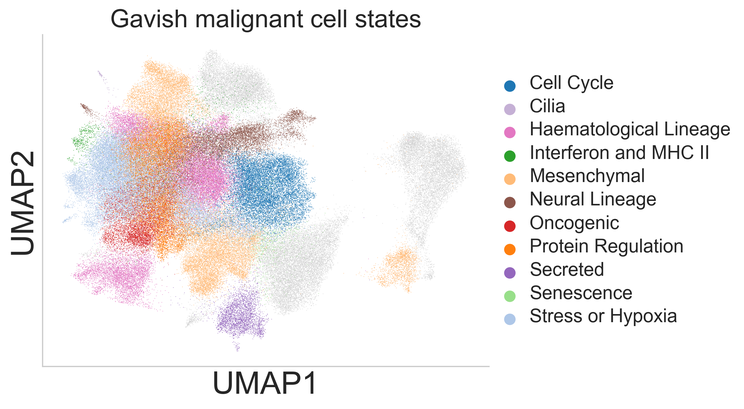

In [22]:
#10 Plot UMAP
plot_col = "Gavish_Hallmark_state_cluster_plot"

tumour.obs[plot_col] = tumour.obs["Gavish_Hallmark_state_cluster"].astype(str)
tumour.obs.loc[tumour.obs[plot_col] == "Normal", plot_col] = np.nan
tumour.obs[plot_col] = tumour.obs[plot_col].astype("category")

sc.pl.umap(tumour,
    color=plot_col, frameon=True, legend_loc="right margin", title="Gavish malignant cell states", na_color="lightgrey", na_in_legend=False, palette=hallmark_palette, show=False,)
ax = plt.gca()

#Removing top and right spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

#Keeping left and bottom spines
ax.spines["left"].set_visible(True)
ax.spines["bottom"].set_visible(True)

#Increasing axis label size
ax.set_xlabel("UMAP1", fontsize=25)
ax.set_ylabel("UMAP2", fontsize=25)

#Increasing tick label size
ax.tick_params(axis="both", labelsize=12)

#Modifying legend
legend = ax.get_legend()
if legend is not None:
    plt.setp(legend.get_texts(), fontsize=15)
    for handle in legend.legend_handles:
        handle.set_sizes([70])

plt.savefig(
    rf"{data_dir}/../Figures/Gavish_Hallmark_state_UMAP.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [23]:
#11 Plotting Heatmap/ Bubble Plot/ Barplot
#0 Shared Gavish Hallmark / Cluster Grouping
#Defining common ordering used by the subsequent plots.
# Structure:
#   Hallmark
#   ->clusters assigned to that Hallmark
#       ->ordered by the Hallmark's defining MP
# The bubble plot later collapses the clusters into one Hallmark column
# Hallmarks ordered as staircase order.

#1 Row order: Gavish MPs grouped by Hallmark
mp_ordered = []
hallmark_row_boundaries = {}
counter = 0

for hallmark, MPs in gavish_hallmarks.items():
    # The "Unassigned" MP group is retained in the data, but will not be displayed in the final Hallmark bubble plot.
    present = [mp
        for mp in MPs
        if mp in robust_mp_scores.columns]

    if len(present) > 0:
        hallmark_row_boundaries[hallmark] = (counter,
            counter + len(present))

        mp_ordered.extend(present)
        counter += len(present)

#2 Cluster and Hallmark labels
cluster_labels = tumour.obs.loc[robust_mp_scores.index, CLUSTER_KEY]
cluster_hallmark = tumour.obs.loc[robust_mp_scores.index, "Gavish_Hallmark_state_cluster"].astype(str)

#3 Cluster-level Hallmark assignment
cluster_to_hallmark = (cluster_hallmark
    .groupby(cluster_labels, observed=True)
    .first())

#4 Per-cluster MP statistics
#Mean robust z-score for each MP in each cluster
mean_z = (robust_mp_scores
    .groupby(cluster_labels, observed=True)
    .mean())


#Fraction of active cells for each MP in each cluster
frac_active = (
    (robust_mp_scores > ACTIVE_THRESHOLD)
    .groupby(cluster_labels, observed=True)
    .mean())

#5 Hallmark staircase
cluster_order = []
hallmark_x_boundaries = [0]
hallmark_labels_x = []
defining_mp_per_hallmark = {}


for hallmark in list(gavish_hallmarks.keys()) + [NO_DOMINANT_LABEL]:
#Clusters assigned to this Hallmark
    clusters_h = (cluster_to_hallmark[cluster_to_hallmark == hallmark]
        .index
        .tolist())

    if not clusters_h:
        continue


    #Biological Hallmark
    if hallmark in gavish_hallmarks:
        present_mps = [mp
            for mp in gavish_hallmarks[hallmark]
            if mp in mean_z.columns]

        if present_mps:
            #Hallmark's defining MP = MP with highest average cluster
            #activity across clusters assigned to this Hallmark
            defining_mp = (mean_z
                .loc[clusters_h, present_mps]
                .mean()
                .idxmax())

            defining_mp_per_hallmark[hallmark] = defining_mp
            #Staircase ordering of clusters
            clusters_h = (mean_z
                .loc[clusters_h, defining_mp]
                .sort_values(ascending=False).index.tolist())

    #No dominant hallmark
    else:
        clusters_h = (mean_z
            .loc[clusters_h, mp_ordered]
            .mean(axis=1)
            .sort_values(ascending=False).index.tolist())

    #Store shared cluster order
    cluster_order.extend(clusters_h)
    hallmark_x_boundaries.append(hallmark_x_boundaries[-1] + len(clusters_h))
    hallmark_labels_x.append(hallmark)


#6 Hallmarks that are actually assigned
hallmark_order_bubble = [
    hallmark
    for hallmark in hallmark_labels_x
    if hallmark != NO_DOMINANT_LABEL
       and hallmark != "Unassigned"]

# Remove duplicates while preserving order
hallmark_order_bubble = list(dict.fromkeys(hallmark_order_bubble))

#7 Cell-level ordering for the heatmap
ordered_chunks = []
hallmark_labels_cells = []
hallmark_cell_boundaries = [0]

cell_cluster_hallmark = tumour.obs.loc[
    robust_mp_scores.index,
    "Gavish_Hallmark_state_cluster"].astype(str)

for hallmark in hallmark_labels_x:
    cells_h = (
        cell_cluster_hallmark[cell_cluster_hallmark == hallmark].index)

    if len(cells_h) == 0:
        continue


    if hallmark in gavish_hallmarks:
        defining_mp = defining_mp_per_hallmark.get(hallmark)

        if defining_mp is not None:
            sub = (
                robust_mp_scores
                .loc[cells_h]
                .sort_values(defining_mp, ascending=False))
        else:
            sub = robust_mp_scores.loc[cells_h]

    else:
        sort_key = (
            robust_mp_scores
            .loc[cells_h,mp_ordered]
            .mean(axis=1).sort_values(ascending=False))
        sub = (robust_mp_scores.loc[cells_h].loc[sort_key.index])

    ordered_chunks.append(sub)
    hallmark_cell_boundaries.append(hallmark_cell_boundaries[-1] + len(sub))
    hallmark_labels_cells.append(hallmark)


#8 Final heatmap cell ordering
plot_df_ordered = pd.concat(ordered_chunks)
hallmark_arr = np.concatenate([np.full(len(chunk), label)
    for chunk, label in zip(
        ordered_chunks, hallmark_labels_cells)])

#9 Ordered cluster matrices
mean_z_ord = mean_z.loc[cluster_order, mp_ordered]
frac_ord = frac_active.loc[cluster_order, mp_ordered]

#10 Summary
print("\nShared Hallmark staircase:")

for i, hallmark in enumerate(hallmark_labels_x, start=1):
    defining_mp = (defining_mp_per_hallmark.get(hallmark, "n/a"))
    print(f"{i:2d}. {hallmark:25s}"
        f"(defining MP: {defining_mp})")

print("\nHallmarks included in aggregated bubble plot:")

for hallmark in hallmark_order_bubble:
    n_clusters = (cluster_to_hallmark.eq(hallmark).sum())
    print(f"  {hallmark:25s}"
          f"n_clusters={n_clusters}")


Shared Hallmark staircase:
 1. Cell Cycle               (defining MP: MP1  Cell Cycle - G2/M)
 2. Stress or Hypoxia        (defining MP: MP5 Stress )
 3. Protein Regulation       (defining MP: MP10 Protein maturation)
 4. Mesenchymal              (defining MP: MP13 EMT-II)
 5. Interferon and MHC II    (defining MP: MP17 Interferon/MHC-II (I))
 6. Senescence               (defining MP: MP19 Epithelial Senescence)
 7. Oncogenic                (defining MP: MP20 MYC)
 8. Secreted                 (defining MP: MP23 Secreted II)
 9. Cilia                    (defining MP: MP24 Cilia)
10. Neural Lineage           (defining MP: MP27 Oligo Progenitor)
11. Haematological Lineage   (defining MP: MP35 Hemato-related-I)

Hallmarks included in aggregated bubble plot:
  Cell Cycle               n_clusters=1
  Stress or Hypoxia        n_clusters=4
  Protein Regulation       n_clusters=2
  Mesenchymal              n_clusters=5
  Interferon and MHC II    n_clusters=2
  Senescence               n_cluste

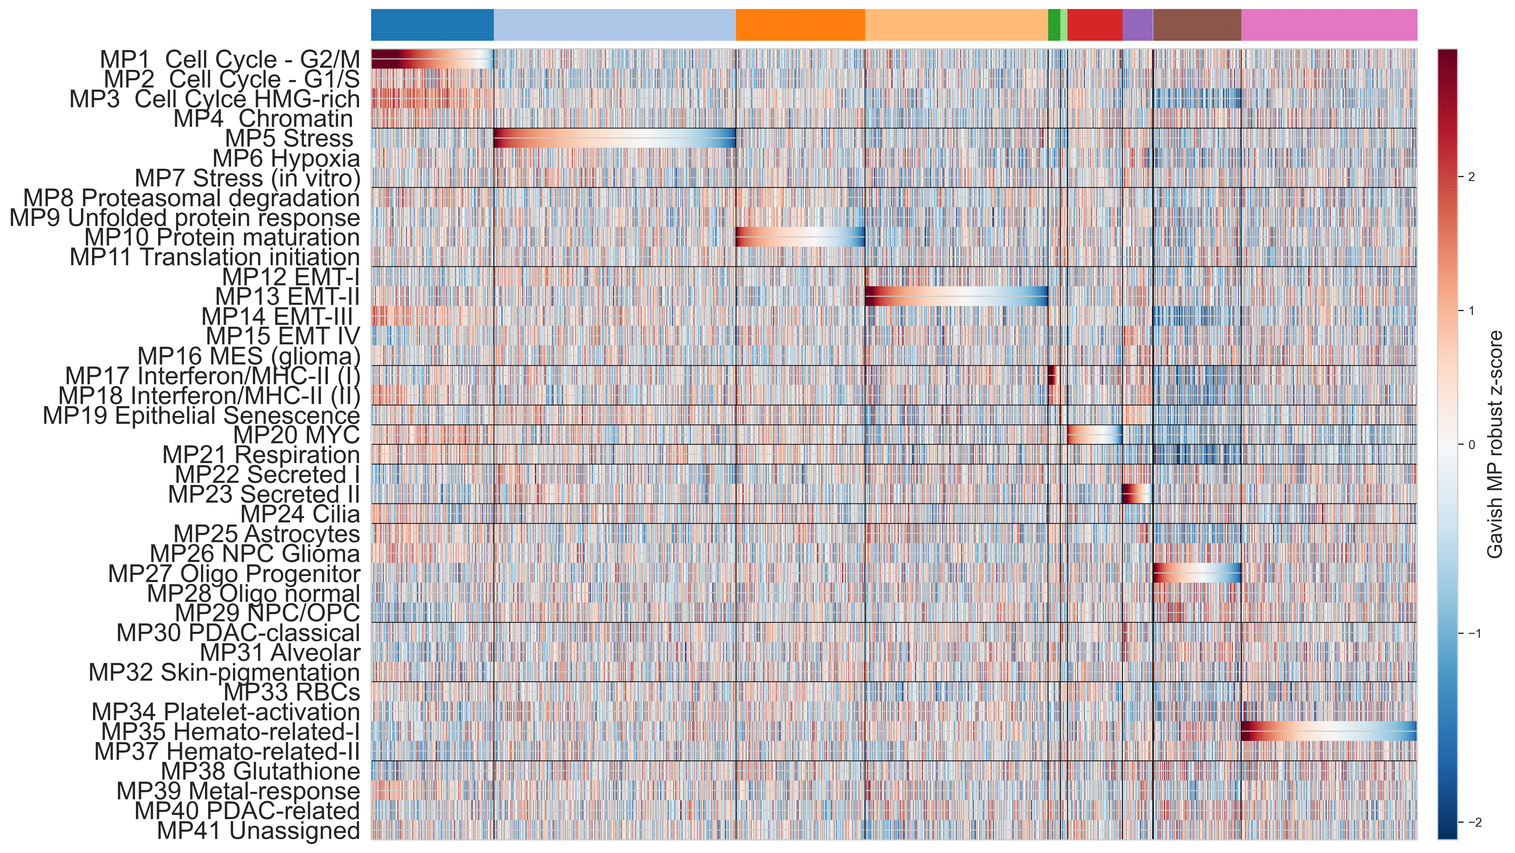

In [24]:
#Plotting: Cell state x Hallmark heatmap
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.gridspec as gridspec
from matplotlib.colors import TwoSlopeNorm

#Row order: MPs grouped by hallmark
#Matrix
mat = plot_df_ordered[mp_ordered].values.T

#Plotting
fig = plt.figure(figsize=(15, 12))
gs = gridspec.GridSpec(2, 1, height_ratios=[0.4, 10], hspace=0.02)
#Hallmark colour strip, using the SAME palette as the UMAP
ax_strip = fig.add_subplot(gs[0])
strip_colors = np.array([hallmark_palette[h]
    for h in hallmark_arr])[None, :, :]

ax_strip.imshow(strip_colors, aspect="auto")

ax_strip.axis("off")

#Heatmap
ax = fig.add_subplot(gs[1])

norm = TwoSlopeNorm(vmin=np.percentile(mat, 1), vcenter=0, vmax=np.percentile(mat, 99))
im = ax.imshow(mat, aspect="auto", cmap="RdBu_r", norm=norm, interpolation="none")

ax.set_yticks(range(len(mp_ordered)))
ax.set_yticklabels(mp_ordered, fontsize=20)
ax.set_xticks([])

#Vertical lines separating Hallmark groups (columns)
for b in hallmark_cell_boundaries[1:-1]:
    ax.axvline(b - 0.5, color="black", linewidth=0.6)

#Horizontal lines separating Hallmark groups (rows)
for hallmark, (start, end) in hallmark_row_boundaries.items():
    if start > 0:
        ax.axhline(start - 0.5, color="black", linewidth=0.6)

#Hallmark labels on colour strip
tick_positions = [(hallmark_cell_boundaries[i] + hallmark_cell_boundaries[i + 1]) / 2
    for i in range(len(hallmark_labels_cells))]

ax_strip.set_xticks(tick_positions)
ax_strip.set_xticklabels(hallmark_labels_cells,
    fontsize=8, rotation=45, ha="left")

ax_strip.xaxis.tick_top()
fig.canvas.draw()

pos = ax.get_position()

cbar_width = 0.015
cbar_pad = 0.015

cax = fig.add_axes([
    pos.x1 + cbar_pad, pos.y0, cbar_width, pos.height])

cbar = fig.colorbar(im, cax=cax)
cbar.set_label("Gavish MP robust z-score")

plt.savefig(
    rf"{data_dir}/../Figures/Gavish_MP_Hallmark_staircase_heatmap.png",
    dpi=300, bbox_inches="tight")
plt.show()


Hallmarks plotted:
['Cell Cycle', 'Stress or Hypoxia', 'Protein Regulation', 'Mesenchymal', 'Interferon and MHC II', 'Senescence', 'Oncogenic', 'Secreted', 'Cilia', 'Neural Lineage', 'Haematological Lineage']

Defining cluster for each Hallmark × MP bubble:

Cell Cycle:
MP1  Cell Cycle - G2/M             cluster=0z=1.76active=63%
MP2  Cell Cycle - G1/S             cluster=0z=0.50active=30%
MP3  Cell Cylce HMG-rich           cluster=0z=1.02active=50%
MP4  Chromatin                     cluster=0z=0.40active=27%
MP5 Stress                         cluster=0z=-0.12active=11%
MP6 Hypoxia                        cluster=0z=0.09active=16%
MP7 Stress (in vitro)              cluster=0z=-0.06active=13%
MP8 Proteasomal degradation        cluster=0z=0.22active=21%
MP9 Unfolded protein response      cluster=0z=-0.02active=14%
MP10 Protein maturation            cluster=0z=0.03active=14%
MP11 Translation initiation        cluster=0z=0.09active=17%
MP12 EMT-I                         cluster=0z=-0.21act

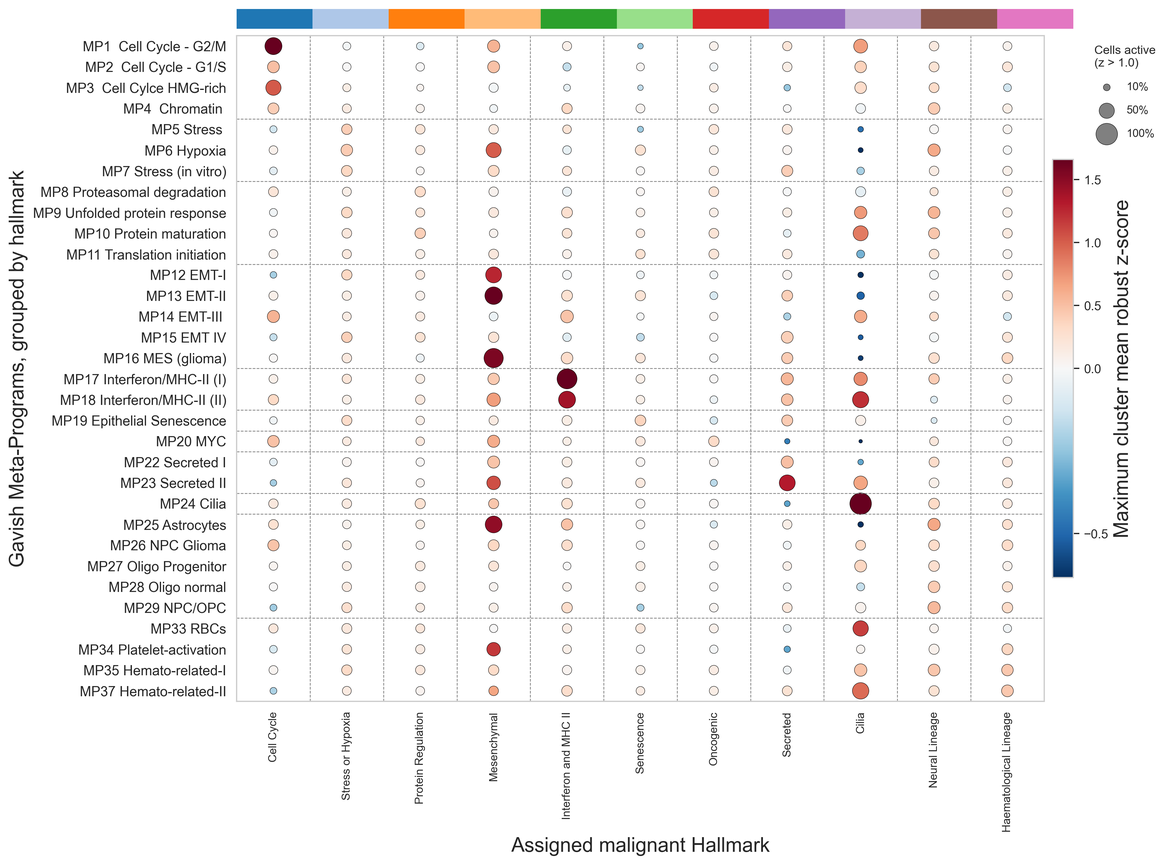

In [26]:
# Bubble Plot: Hallmark x Gavish MP
# For every Hallmark x MP combination:
#     1. Identify all clusters assigned to that Hallmark.
#     2. Calculate the cluster-level mean MP z-score.
#     3. Find the cluster with the strongest mean MP z-score.
#     4. Use that maximum cluster-level value as the bubble colour.
#     5. Use the active-cell fraction from THAT SAME cluster as bubble size.
# This preserves different cell states within the same Hallmark.
#
# Example:
#     Mesenchymal
#         Cluster 3  -> MP12 high
#         Cluster 8  -> MP14 high
# The resulting Mesenchymal column can therefore show:
#         MP12  high
#         MP14  high
# instead of averaging the two clusters into two weak signals.

# 1. Determine Hallmarks to display
hallmarks_to_plot = [
    hallmark
    for hallmark in hallmark_order_bubble
    if hallmark in cluster_to_hallmark.values
]

#staircase order
hallmarks_to_plot = list(
    dict.fromkeys(hallmarks_to_plot))
print("\nHallmarks plotted:")
print(hallmarks_to_plot)

#2 Restrict MP rows to biological Hallmarks that are represented
mp_ordered_bubble = []
bubble_row_boundaries = {}
counter = 0

for hallmark in gavish_hallmarks.keys():
    # Skip the Gavish "Unassigned" MP bucket
    if hallmark == "Unassigned":
        continue
    # Skip Hallmarks with no assigned clusters
    if hallmark not in hallmarks_to_plot:
        continue

    present = [
        mp
        for mp in gavish_hallmarks[hallmark]
        if mp in robust_mp_scores.columns
    ]

    if not present:
        continue

    bubble_row_boundaries[hallmark] = (counter, counter + len(present))
    mp_ordered_bubble.extend(present)
    counter += len(present)

#3 Calculate Hallmark x MP values
#NO averaging across clusters here.
# For each Hallmark and MP: max cluster mean z-score
# determines the colour.
# The active fraction from that SAME cluster determines the bubble size.

bubble_mean_z = pd.DataFrame(
    index=hallmarks_to_plot, columns=mp_ordered_bubble, dtype=float)
bubble_frac_active = pd.DataFrame(
    index=hallmarks_to_plot, columns=mp_ordered_bubble, dtype=float)
# Keep track of which cluster produced each bubble
bubble_defining_cluster = pd.DataFrame(
    index=hallmarks_to_plot, columns=mp_ordered_bubble, dtype=object)

for hallmark in hallmarks_to_plot:
    # Clusters assigned to this Hallmark

    clusters_h = (
        cluster_to_hallmark[cluster_to_hallmark == hallmark]
        .index.tolist()
    )

    if not clusters_h:
        continue

    # For EACH MP, find the strongest cluster
    for mp in mp_ordered_bubble:
        if mp not in mean_z.columns:
            continue
        # Cluster-level mean z-scores for this MP
        cluster_z = (
            mean_z.loc[clusters_h, mp]
            .dropna())
        if cluster_z.empty:
            continue


        best_cluster = cluster_z.idxmax()#Strongest cluster for THIS specific MP
        best_z = cluster_z.loc[best_cluster]#Mean z-score used for bubble colour
        best_frac = frac_active.loc[best_cluster, mp]# Active fraction from the SAME cluster
        bubble_mean_z.loc[hallmark,mp] = best_z
        bubble_frac_active.loc[hallmark, mp] = best_frac
        bubble_defining_cluster.loc[hallmark, mp] = best_cluster

#4 Print which cluster defines each Hallmark x MP bubble
print("\nDefining cluster for each Hallmark × MP bubble:")
for hallmark in hallmarks_to_plot:
    print(f"\n{hallmark}:")
    for mp in mp_ordered_bubble:
        cluster = bubble_defining_cluster.loc[hallmark, mp]
        if pd.notna(cluster):
            z = bubble_mean_z.loc[hallmark, mp]
            frac = bubble_frac_active.loc[hallmark, mp]
            print(f"{mp:35s}" f"cluster={cluster}" f"z={z:.2f}" f"active={frac:.0%}")

#5 Coordinates
DOT_SCALE = 300#marker area (points^2) for a cluster where 100% of cells are active
n_hallmarks = len(hallmarks_to_plot)
n_mps = len(mp_ordered_bubble)
xx, yy = np.meshgrid(np.arange(n_hallmarks), np.arange(n_mps))
colors = (bubble_mean_z.values.T.flatten())
sizes = (bubble_frac_active.values.T.flatten()* DOT_SCALE)


#6Figure
fig = plt.figure(figsize=(max(12, n_hallmarks * 0.8), max(10, n_mps * 0.3)))
gs = gridspec.GridSpec(2, 1, height_ratios=[0.3, 10], hspace=0.02)

#7 Hallmark colour strip
ax_strip = fig.add_subplot(gs[0])

strip_arr = np.array([hallmark_palette[h]for h in hallmarks_to_plot])[None, :, :]
ax_strip.imshow(strip_arr, aspect="auto")

ax_strip.axis("off")
ax_strip.set_xlim(-0.5, n_hallmarks - 0.5)
ax_strip.set_xticks(np.arange(n_hallmarks))
ax_strip.set_xticklabels(hallmarks_to_plot, fontsize=9, rotation=45, ha="left")
ax_strip.xaxis.tick_top()

#8Main bubble plot
ax = fig.add_subplot(gs[1])
valid_colors = colors[np.isfinite(colors)]# Robust colour range

norm = TwoSlopeNorm(vmin=np.nanpercentile(valid_colors, 1),
    vcenter=0, vmax=np.nanpercentile(valid_colors, 99))

sc_plot = ax.scatter(xx.flatten(), yy.flatten(), s=sizes, c=colors, cmap="RdBu_r", norm=norm, edgecolor="black", linewidth=0.3)

ax.set_xlim(-0.5, n_hallmarks - 0.5)
ax.set_ylim(-0.5, n_mps - 0.5)
ax.invert_yaxis()

#9 X-axis = Hallmarks
ax.set_xticks(range(n_hallmarks))
ax.set_xticklabels(hallmarks_to_plot, fontsize=9, rotation=90)

#10 Y-axis = Gavish MPs
ax.set_yticks(range(n_mps))
ax.set_yticklabels(mp_ordered_bubble, fontsize=11)

#11 Staircase separators
# Vertical lines between Hallmark columns
for b in range(1, n_hallmarks):
    ax.axvline(b - 0.5, color="grey", linewidth=0.6, linestyle="--")

# Horizontal lines between groups of MPs belonging to different Hallmarks
for hallmark, (start, end) in bubble_row_boundaries.items():
    if start > 0:
        ax.axhline(start - 0.5, color="grey", linewidth=0.6, linestyle="--")

#12 Axis labels
ax.set_xlabel("Assigned malignant Hallmark")
ax.set_ylabel("Gavish Meta-Programs, grouped by hallmark")

ax.grid(False)

#13 Colourbar
cbar = fig.colorbar(sc_plot, ax=ax, pad=0.01, fraction=0.025)
cbar.set_label("Maximum cluster mean robust z-score")

#14 Bubble-size legend
for frac in [0.1, 0.5, 1.0]:
    ax.scatter([], [], s=frac * DOT_SCALE, color="grey", edgecolor="black", linewidth=0.3, label=f"{int(frac * 100)}%")

ax.legend(
    title=(f"Cells active\n"
        f"(z > {ACTIVE_THRESHOLD})"),
    loc="upper left", bbox_to_anchor=(1.05, 1.0), frameon=False, labelspacing=1.2)

#15 Save
plt.savefig(rf"{data_dir}/../Figures/Gavish_MP_Hallmark_bubbleplot.png",
    dpi=300, bbox_inches="tight")
plt.show()

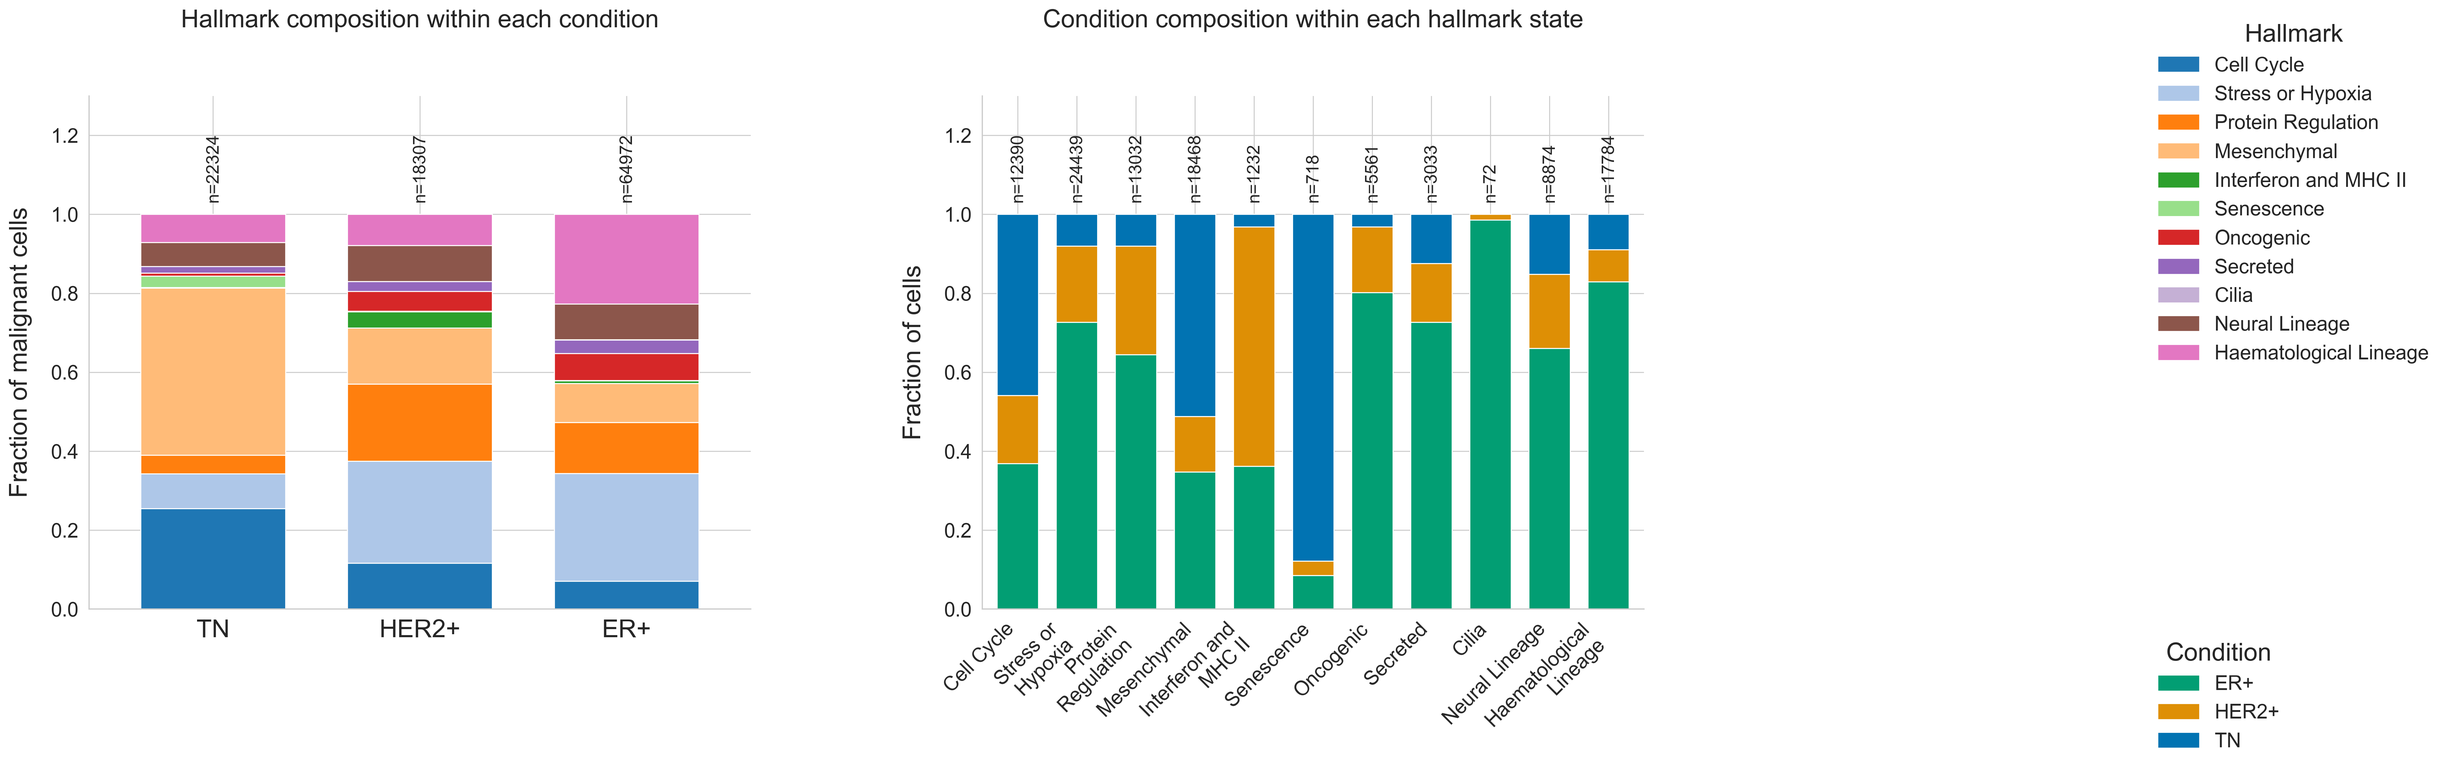

Chi-square test for condition x hallmark association:chi2=27969.6, dof=20, p=0.00e+00


In [27]:
#Plotting: Hallmark state distribution across conditions
import textwrap
dist_df = tumour.obs.loc[mask,
    ["condition", "Gavish_Hallmark_state_cluster"]].copy()

dist_df = dist_df.rename(
    columns={"Gavish_Hallmark_state_cluster": "hallmark"})

#Use the SAME Hallmark order as the heatmap and bubble plot
hallmarks_present = [h
    for h in hallmark_labels_x
    if h in dist_df["hallmark"].unique()]


conditions_present = sorted(
    dist_df["condition"].unique())


if ("condition_colors" in tumour.uns
        and len(tumour.uns["condition_colors"])
        == len(tumour.obs["condition"].cat.categories)):
    condition_palette = dict(
        zip(tumour.obs["condition"].cat.categories,
            tumour.uns["condition_colors"]))

    condition_palette = {
        c: condition_palette[c]
        for c in conditions_present}

else:
    condition_palette = dict(
        zip(conditions_present,
            sns.color_palette("Set2", len(conditions_present))))

#Figure
fig, axes = plt.subplots(1, 2, figsize=(24, 10))
#Panel 1
ct1 = pd.crosstab(dist_df["condition"], dist_df["hallmark"], normalize="index")
ct1 = ct1.reindex(columns=hallmarks_present)
ct1.plot(kind="bar", stacked=True, ax=axes[0], color=[hallmark_palette[h]
        for h in ct1.columns], width=0.7, legend=False,)

axes[0].set_title("Hallmark composition within each condition",
    fontsize=20, pad=55)
axes[0].set_xlabel("")
axes[0].set_ylabel("Fraction of malignant cells",
    fontsize=20, labelpad=15)
axes[0].tick_params(axis="x", rotation=0, labelsize=20)
axes[0].tick_params(axis="y", labelsize=16)
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)
axes[0].set_ylim(0, 1.30)

n_per_condition = (dist_df["condition"]
    .value_counts())

for i, cond in enumerate(ct1.index):
    axes[0].text(i, 1.03,
        f"n={n_per_condition[cond]}",
        ha="center", va="bottom", rotation=90, fontsize=14)

#Panel 2
ct2 = pd.crosstab(dist_df["hallmark"], dist_df["condition"], normalize="index")
ct2 = ct2.reindex(index=hallmarks_present, columns=conditions_present)
ct2.plot(kind="bar", stacked=True, ax=axes[1], color=[condition_palette[c]
        for c in ct2.columns], width=0.7, legend=False)

axes[1].set_title("Condition composition within each hallmark state",
                  fontsize=20, pad=55)
axes[1].set_xlabel("")
axes[1].set_ylabel("Fraction of cells",
                   fontsize=20, labelpad=15)

# Wrap long hallmark names
wrapped_labels = [textwrap.fill(h, width=14)
    for h in ct2.index]

axes[1].set_xticklabels(wrapped_labels, rotation=45, ha="right", fontsize=16)
axes[1].tick_params(axis="y", labelsize=16)
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)
axes[1].set_ylim(0, 1.30)

n_per_hallmark = (dist_df["hallmark"]
    .value_counts())

for i, h in enumerate(ct2.index):
    axes[1].text(i, 1.03,
        f"n={n_per_hallmark.get(h, 0)}",
        ha="center", va="bottom", rotation=90, fontsize=14)

#Legends
hallmark_handles = [
    plt.Rectangle((0, 0), 1, 1, color=hallmark_palette[h])
    for h in hallmarks_present]
condition_handles = [
    plt.Rectangle((0, 0), 1, 1, color=condition_palette[c])
    for c in conditions_present]
legend1_top = 0.95

legend1 = fig.legend(hallmark_handles, hallmarks_present,
                     title="Hallmark", title_fontsize=20, loc="upper left", bbox_to_anchor=(1.01, legend1_top), fontsize=16, frameon=False,)
legend2_top = (legend1_top
               - 0.055 * (len(hallmarks_present) + 1.5))
fig.legend(condition_handles, conditions_present,
           title="Condition", title_fontsize=20, loc="upper left", bbox_to_anchor=(1.01, legend2_top), fontsize=16, frameon=False)
fig.subplots_adjust(left=0.06, right=0.78, top=0.85, bottom=0.28, wspace=0.35)

#Save
plt.savefig(rf"{data_dir}/../Figures/Gavish_Hallmark_condition_distribution.png",
    dpi=300, bbox_inches="tight")
plt.show()

#Statistical association
from scipy.stats import chi2_contingency
contingency = pd.crosstab(dist_df["condition"], dist_df["hallmark"])
chi2, p, dof, expected = chi2_contingency(contingency)
print(f"Chi-square test for condition x hallmark association:"#
      f"chi2={chi2:.1f}, dof={dof}, p={p:.2e}")

Plotting: Stacked bar

STEP 10: EMT Score

In [28]:
import matplotlib.patches as mpatches
#Gavish Mesenchymal Hallmark score per cell
mesenchymal_MPs = gavish_hallmarks["Mesenchymal"]

#Keep only MPs present in the dataset
mesenchymal_MPs_present = [
    mp for mp in mesenchymal_MPs
    if mp in robust_mp_scores.columns
]

print("Mesenchymal MPs detected:",len(mesenchymal_MPs_present),"/",len(mesenchymal_MPs))
#Average Mesenchymal MP activity per malignant cell
mesenchymal_score = (robust_mp_scores[mesenchymal_MPs_present].mean(axis=1))

#Add to tumour object
tumour.obs["Gavish_Mesenchymal_score"] = np.nan
tumour.obs.loc[mask, "Gavish_Mesenchymal_score"] = mesenchymal_score.values

Mesenchymal MPs detected: 5 / 5


In [29]:
#Cpólours: ROR1 / EGFR group colour palette
group_palette = {
    "Double negative": "#BDBDBD",
    "EGFR only": "#4C72B0",
    "ROR1 only": "#DD8452",
    "Double positive": "#55A868"
}

In [30]:
#EGFR / ROR1 expression + co-expression grouping
egfr_idx = tumour.var_names.get_loc("EGFR")
egfr_expr = tumour.X[:, egfr_idx]   #confirming layers

if sp.issparse(egfr_expr):
    egfr_expr = np.asarray(egfr_expr.todense()).flatten()

tumour.obs["EGFR"] = egfr_expr

#Co-expression grouping
ROR1_thr = 0.5
EGFR_thr = 0.5

ror1_pos = tumour.obs["ROR1_alra"] > ROR1_thr
egfr_pos = tumour.obs["EGFR"] > EGFR_thr

tumour.obs["ROR1_EGFR_group"] = "Double negative"
tumour.obs.loc[ror1_pos & ~egfr_pos, "ROR1_EGFR_group"] = "ROR1 only"
tumour.obs.loc[~ror1_pos & egfr_pos, "ROR1_EGFR_group"] = "EGFR only"
tumour.obs.loc[ror1_pos & egfr_pos,  "ROR1_EGFR_group"] = "Double positive"

tumour.obs["ROR1_EGFR_group"] = pd.Categorical(
    tumour.obs["ROR1_EGFR_group"],
    categories=["Double negative", "EGFR only", "ROR1 only", "Double positive"],
    ordered=True
)

doublepos_mask = tumour.obs["ROR1_EGFR_group"] == "Double positive"

print(tumour.obs["ROR1_EGFR_group"].value_counts())
print(f"\nDouble positive cells: {doublepos_mask.sum():,} "
      f"({doublepos_mask.mean()*100:.2f}%)")

ROR1_EGFR_group
Double negative    114009
EGFR only           14907
ROR1 only            3568
Double positive       756
Name: count, dtype: int64

Double positive cells: 756 (0.57%)


In [31]:
#EPCAM / ERBB2 expression + co-expression grouping
for gene in ["EPCAM", "ERBB2"]:
    gene_idx = tumour.var_names.get_loc(gene)
    gene_expr = tumour.X[:, gene_idx]

    if sp.issparse(gene_expr):
        gene_expr = np.asarray(gene_expr.todense()).flatten()

    tumour.obs[gene] = gene_expr

#Co-expression grouping
EPCAM_thr = 2
ERBB2_thr = 2

epcam_pos = tumour.obs["EPCAM"] > EPCAM_thr
erbb2_pos = tumour.obs["ERBB2"] > ERBB2_thr

tumour.obs["EPCAM_ERBB2_group"] = "Double negative"
tumour.obs.loc[epcam_pos & ~erbb2_pos, "EPCAM_ERBB2_group"] = "EPCAM only"
tumour.obs.loc[~epcam_pos & erbb2_pos, "EPCAM_ERBB2_group"] = "ERBB2 only"
tumour.obs.loc[epcam_pos & erbb2_pos,  "EPCAM_ERBB2_group"] = "Double positive"

tumour.obs["EPCAM_ERBB2_group"] = pd.Categorical(
    tumour.obs["EPCAM_ERBB2_group"],
    categories=["Double negative", "EPCAM only", "ERBB2 only", "Double positive"],
    ordered=True)

doublepos_mask_epcam_erbb2 = tumour.obs["EPCAM_ERBB2_group"] == "Double positive"

print(tumour.obs["EPCAM_ERBB2_group"].value_counts())
print(f"\nDouble positive cells: {doublepos_mask_epcam_erbb2.sum():,} "
      f"({doublepos_mask_epcam_erbb2.mean()*100:.2f}%)")

EPCAM_ERBB2_group
Double negative    93754
EPCAM only         18838
ERBB2 only         11564
Double positive     9084
Name: count, dtype: int64

Double positive cells: 9,084 (6.82%)


['Cell Cycle', 'Stress or Hypoxia', 'Protein Regulation', 'Mesenchymal', 'Interferon and MHC II', 'Senescence', 'Oncogenic', 'Secreted', 'Cilia', 'Neural Lineage', 'Haematological Lineage']


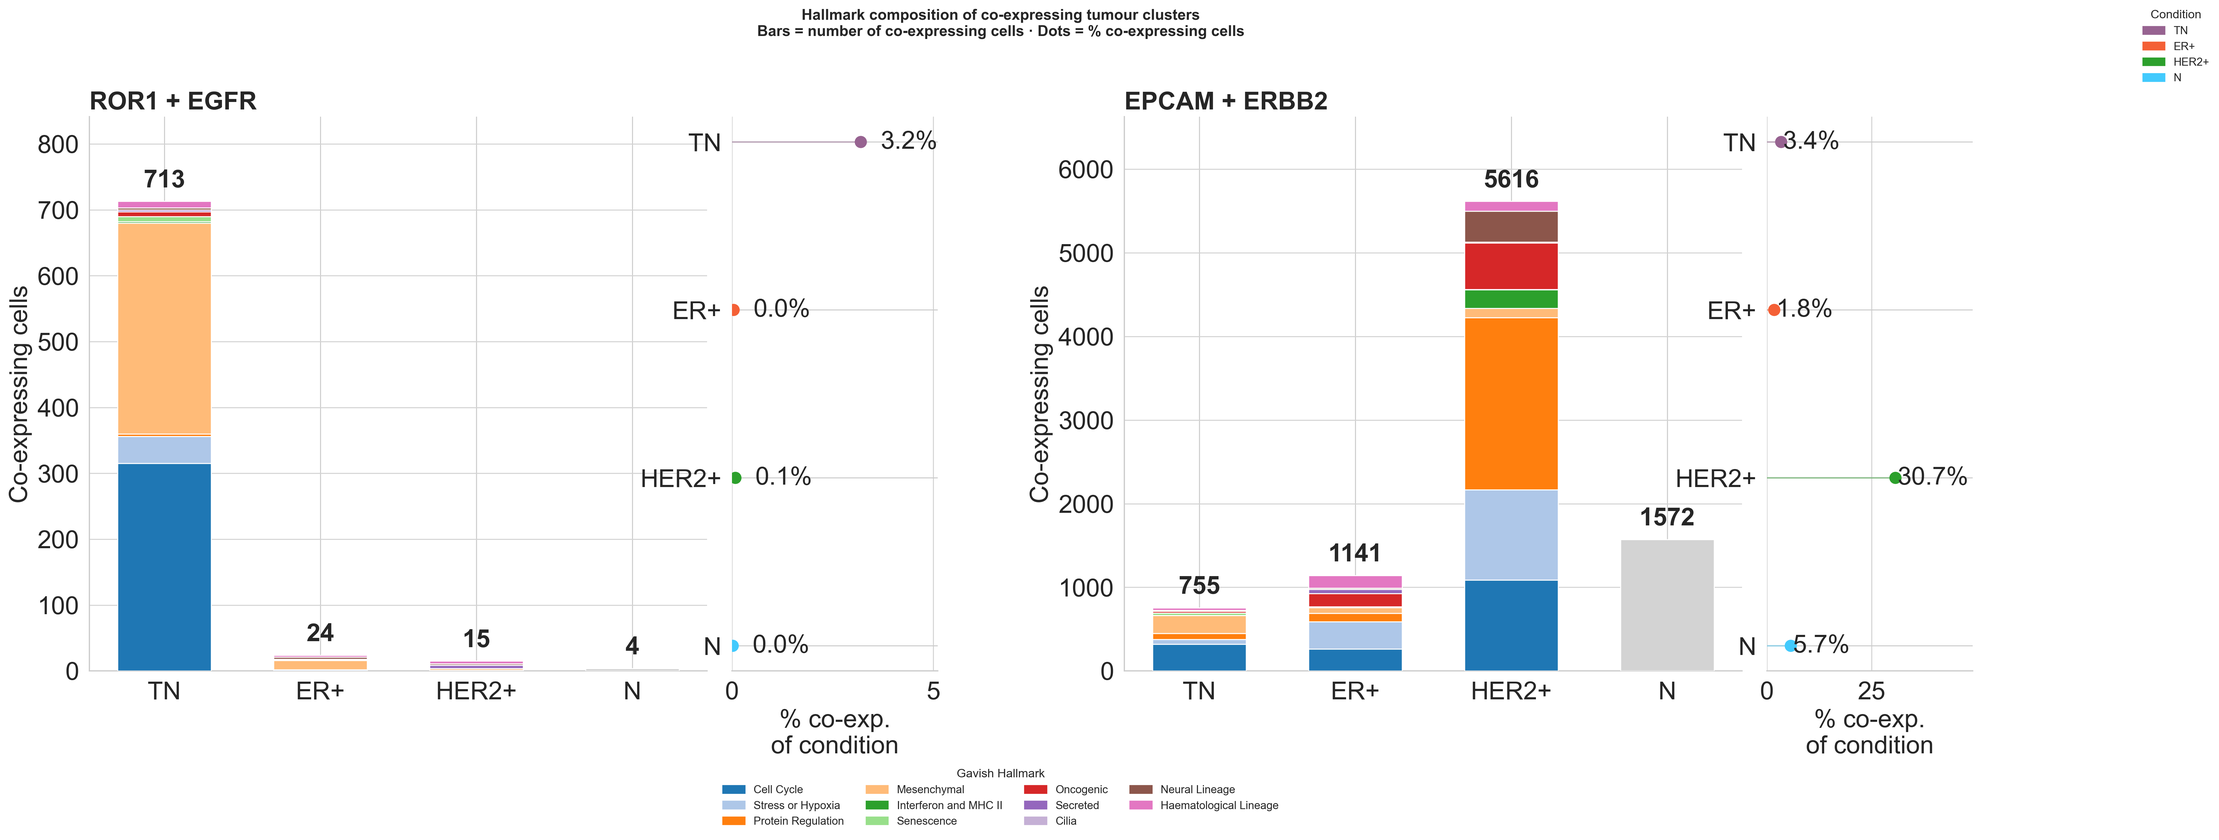

In [32]:
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
#Data preparation
plot_col = "Gavish_Hallmark_state_cluster_plot"

conditions = ["TN", "ER+", "HER2+", "N"]

cond_colors = [
    "#976391",
    "#F46036",
    "#2CA02C",
    "#42CAFD"]

states = [
    "Normal",
    "Cell Cycle",
    "Stress or Hypoxia",
    "Protein Regulation",
    "Mesenchymal",
    "Interferon and MHC II",
    "Senescence",
    "Oncogenic",
    "Respiration",
    "Secreted",
    "Cilia",
    "Neural Lineage",
    "Other Lineage",
    "Haematological Lineage",
    "Unassigned"]

states = [
    s for s in states
    if s in tumour.obs[plot_col].cat.categories]

print(states)

panel_configs = {
    "ror1_egfr": (
        "ROR1 + EGFR",
        (tumour.obs["ROR1_EGFR_group"] == "Double positive").values),
    "epcam_erbb2": (
        "EPCAM + ERBB2",
        (tumour.obs["EPCAM_ERBB2_group"] == "Double positive").values)}

def compute_panel(coexp_mask):
    counts = {}
    totals = {}
    pct_coexp = {}

    for cond in conditions:
        cond_mask = (tumour.obs["condition"] == cond).values
        cond_coexp = cond_mask & coexp_mask

        n_cond = cond_mask.sum()
        totals[cond] = cond_coexp.sum()

        pct_coexp[cond] = (totals[cond] / n_cond * 100
            if n_cond > 0 else 0)

        counts[cond] = {}

        for state in states:
            state_mask = (tumour.obs[plot_col] == state).values
            counts[cond][state] = (cond_coexp & state_mask).sum()
    return counts, totals, pct_coexp

#Figure layout
fig = plt.figure(figsize=(27, 8))

outer = gridspec.GridSpec(1, 2, figure=fig, wspace=0.22)
axes = {}

for col_idx, (key, (title, mask)) in enumerate(panel_configs.items()):
    inner = gridspec.GridSpecFromSubplotSpec(
        1, 2, subplot_spec=outer[col_idx], width_ratios=[4.5, 1.5], wspace=0.06)
    axes[key] = (
        fig.add_subplot(inner[0]),
        fig.add_subplot(inner[1]),
        title, mask)

#Draw panels
for key, (ax_bar, ax_dot, title, mask) in axes.items():
    counts, totals, pct = compute_panel(mask)

    x = np.arange(len(conditions))
    bottom = np.zeros(len(conditions))

    for state in states:
        vals = np.array([
            counts[c][state] if c != "N" else 0   # never stack hallmark states onto the N bar
            for c in conditions])

        ax_bar.bar(
            x, vals, bottom=bottom, width=0.6, color=hallmark_palette.get(state, "lightgrey"), zorder=3)
        bottom += vals

    #separate solid bar for N, showing the total co-expressing count with no state colour
    n_idx = conditions.index("N")
    n_total = totals["N"]

    ax_bar.bar(n_idx, n_total, width=0.6, color="lightgrey", zorder=3)
    #Add total count above each bar
    for xi, cond in enumerate(conditions):
        total = totals[cond]
        if total > 0:
            ax_bar.text(xi,
                total + max(totals.values()) * 0.02, str(int(total)),
                ha="center", va="bottom", fontsize=20, fontweight="bold")

    ax_bar.set_xticks(x)
    ax_bar.set_xticklabels(conditions, fontsize=20)
    ax_bar.set_ylabel("Co-expressing cells", fontsize=20)
    ax_bar.set_ylim(0, max(totals.values()) * 1.18)
    ax_bar.tick_params(axis="y", labelsize=20)
    ax_bar.set_title(title, loc="left", fontsize=20, fontweight="bold")
    ax_bar.grid(axis="y", color="lightgrey")
    ax_bar.spines[["top", "right"]].set_visible(False)

    #dot plot — unchanged, already used `pct` which is now correctly non-zero for N too
    for ci, (cond, color) in enumerate(zip(conditions, cond_colors)):
        ax_dot.scatter(pct[cond], ci, color=color, s=80)
        ax_dot.plot([0, pct[cond]], [ci, ci], color=color, alpha=0.4)
        ax_dot.text(pct[cond] + 0.5, ci, f"{pct[cond]:.1f}%", fontsize=20, va="center")

    max_pct = max(pct.values())
    ax_dot.set_xlim(0, max_pct * 1.6 if max_pct > 0 else 1)
    ax_dot.set_yticks(range(len(conditions)))
    ax_dot.set_yticklabels(conditions, fontsize=20)
    ax_dot.invert_yaxis()
    ax_dot.set_xlabel("% co-exp.\nof condition", fontsize=20)
    ax_dot.spines[["top", "right", "left"]].set_visible(False)
    ax_dot.tick_params(axis="x", labelsize=20)
    ax_dot.grid(axis="x", color="lightgrey")

# Legends
fig.legend(
    handles=[
        mpatches.Patch(color=hallmark_palette.get(s, "lightgrey"), label=s)
        for s in states],
    title="Gavish Hallmark", loc="lower center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)

fig.legend(
    handles=[mpatches.Patch(color=c, label=cond)
             for cond, c in zip(conditions, cond_colors)],
    title="Condition", loc="upper right", frameon=False)

plt.suptitle(
    "Hallmark composition of co-expressing tumour clusters\n"
    "Bars = number of co-expressing cells · Dots = % co-expressing cells",
    fontsize=12, fontweight="bold", y=1.03)
plt.savefig(rf"{data_dir}/../Figures/Gavish_cluster_hallmark_composition.png",
    dpi=300, bbox_inches="tight")
plt.show()

/var/folders/kn/dz8n2v_j7cq3qn3h60y7qmwh0000gp/T/ipykernel_67537/1739675563.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(data=tumour.obs,


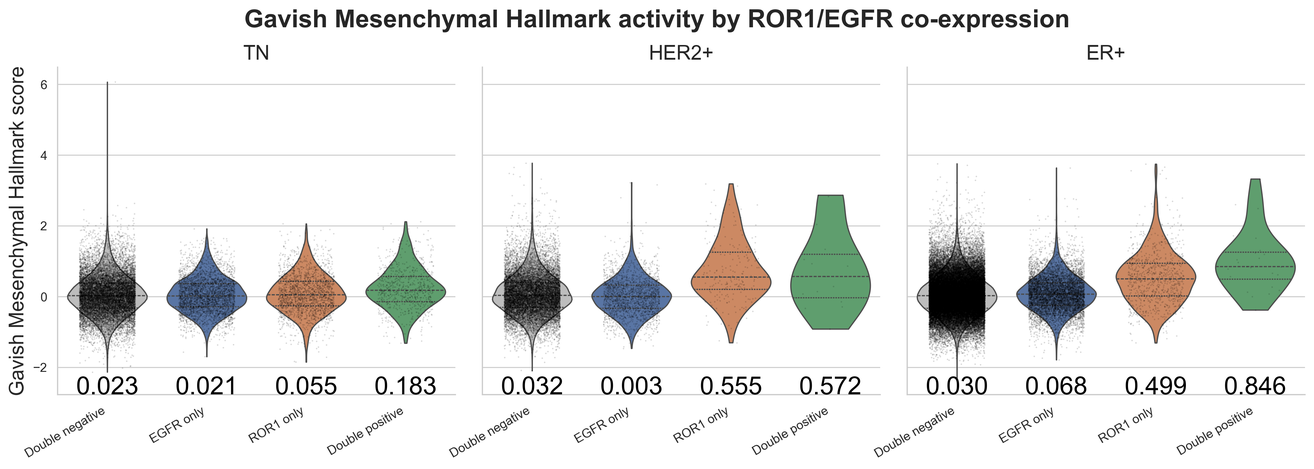

In [33]:
#Condition order
col_order = ["TN", "HER2+", "ER+"]
order = ["Double negative", "EGFR only", "ROR1 only", "Double positive"]

#Violin plot
g = sns.catplot(data=tumour.obs,
                x="ROR1_EGFR_group", y="Gavish_Mesenchymal_score", col="condition", col_order=col_order, kind="violin", inner="quartile", palette=group_palette, order=order, height=5, aspect=1, cut=0)

#Overlay individual cells + median values
for ax, cond in zip(g.axes.flat, col_order):
    cond_data = tumour.obs[tumour.obs["condition"] == cond]

    #single cell points
    sns.stripplot(data=cond_data, x="ROR1_EGFR_group", y="Gavish_Mesenchymal_score", order=order, ax=ax, color="black",
                  size=1.2, alpha=0.15, jitter=0.28)

    #median annotations
    for xi, cat in enumerate(order):
        med = (cond_data
            .loc[cond_data["ROR1_EGFR_group"] == cat,
                "Gavish_Mesenchymal_score"]
            .median())

        if not np.isnan(med):
            ax.text(xi, ax.get_ylim()[0] + 0.01, f"{med:.3f}", ha="center", fontsize=20, color="black")
    #zero reference
    ax.axhline(0, color="gray", linewidth=0.6, linestyle="--", zorder=0)

#Labels and formatting
g.set_titles("{col_name}")
g.set_axis_labels("", "Gavish Mesenchymal Hallmark score")
g.set_xticklabels(rotation=30, ha="right")

plt.suptitle(
    "Gavish Mesenchymal Hallmark activity by ROR1/EGFR co-expression", fontsize=20, fontweight="bold", y=1.02)

plt.savefig(rf"{data_dir}/../Figures/Gavish_Mesenchymal_score_coexpression_by_condition.png",
    dpi=300, bbox_inches="tight")
plt.show()

/var/folders/kn/dz8n2v_j7cq3qn3h60y7qmwh0000gp/T/ipykernel_67537/858278826.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(data=tumour.obs,


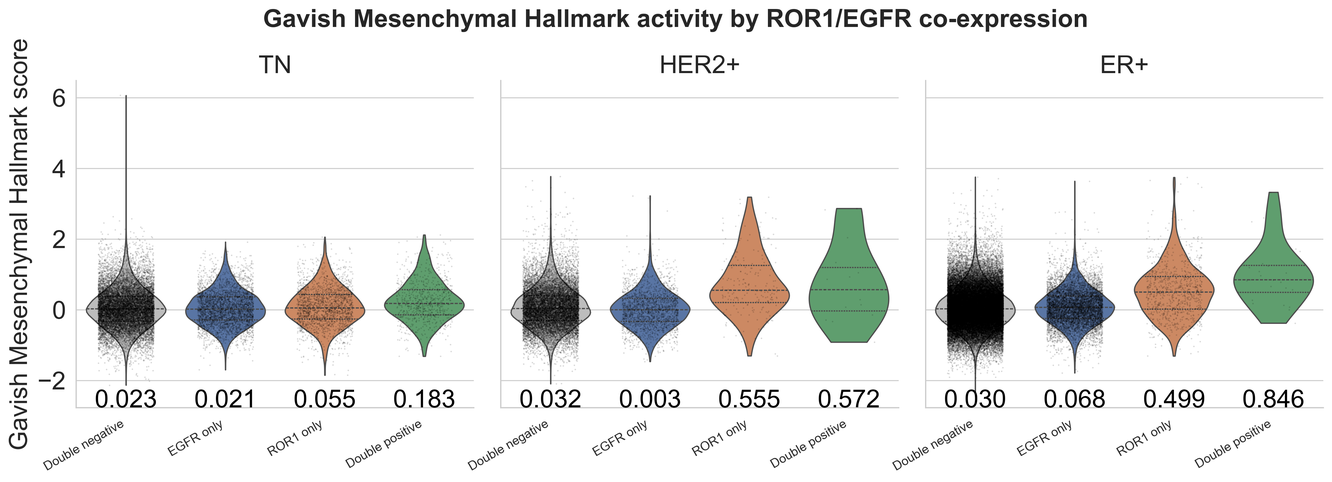

In [34]:
#Gavish Mesenchymal Hallmark score by ROR1/EGFR group and condition
FONTSIZE = 20
# Condition order
col_order = ["TN", "HER2+", "ER+"]
# ROR1 / EGFR group order
order = [
    "Double negative",
    "EGFR only",
    "ROR1 only",
    "Double positive"]

#Violin plot
g = sns.catplot(data=tumour.obs,
                x="ROR1_EGFR_group", y="Gavish_Mesenchymal_score", col="condition", col_order=col_order, kind="violin", inner="quartile", palette=group_palette, order=order, height=5, aspect=1, cut=0)

#Overlay individual cells + median values
for ax, cond in zip(g.axes.flat, col_order):
    cond_data = tumour.obs[
        tumour.obs["condition"] == cond]

    #single cell points
    sns.stripplot(data=cond_data,
                  x="ROR1_EGFR_group", y="Gavish_Mesenchymal_score", order=order, ax=ax, color="black", size=1.2, alpha=0.15, jitter=0.28)

    #median annotations
    for xi, cat in enumerate(order):
        med = (cond_data
            .loc[cond_data["ROR1_EGFR_group"] == cat, "Gavish_Mesenchymal_score"]
            .median())

        if not np.isnan(med):
            ax.text(xi, ax.get_ylim()[0] + 0.01, f"{med:.3f}", ha="center", fontsize=FONTSIZE, color="black")

    #zero reference
    ax.axhline(0, color="gray", linewidth=0.6, linestyle="--", zorder=0)
    #y tick label size (not covered by set_titles/set_axis_labels/set_xticklabels below)
    ax.tick_params(axis="y", labelsize=FONTSIZE)

#Labels and formatting
g.set_titles("{col_name}", size=FONTSIZE)
g.set_axis_labels("", "Gavish Mesenchymal Hallmark score", fontsize=FONTSIZE)
g.set_xticklabels(rotation=30, ha="right")

plt.suptitle("Gavish Mesenchymal Hallmark activity by ROR1/EGFR co-expression",
    fontsize=FONTSIZE, fontweight="bold", y=1.05)#nudged up slightly to clear the now-larger facet titles
plt.savefig(rf"{data_dir}/../Figures/Gavish_Mesenchymal_score_coexpression_by_condition.png",
    dpi=300, bbox_inches="tight")
plt.show()

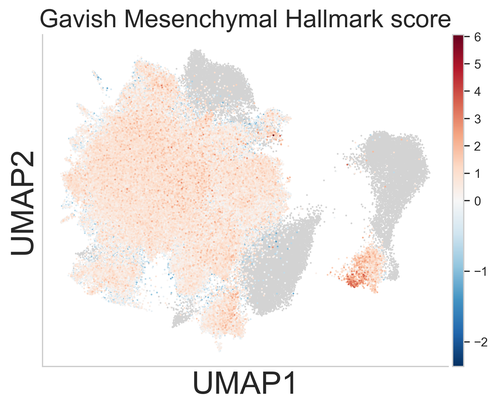

In [35]:
#UMAP — Gavish Mesenchymal Hallmark score
sc.pl.umap(tumour,
    color="Gavish_Mesenchymal_score", frameon=True, title="Gavish Mesenchymal Hallmark score", cmap="RdBu_r", vcenter=0,          # diverging colormap centered at 0, matching your heatmap's TwoSlopeNorm
    na_color="lightgrey", size=8, show=False,)

ax = plt.gca()

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(True)
ax.spines["bottom"].set_visible(True)

ax.set_xlabel("UMAP1", fontsize=25)
ax.set_ylabel("UMAP2", fontsize=25)
ax.tick_params(axis="both", labelsize=12)

#colourbar label + tick size (scanpy names this axis "cbar" via the last colorbar it created)
cbar = fig.axes[-1]  ## the colourbar is the last axes scanpy added to the current figure
cbar.set_ylabel("Robust z-score", fontsize=14)
cbar.tick_params(labelsize=12)

plt.savefig(rf"{data_dir}/../Figures/Gavish_Mesenchymal_score_UMAP.png",
    dpi=300, bbox_inches="tight")
plt.show()

STEP 11: MALTA-Stemness Score

In [36]:
from scipy.stats import mannwhitneyu, kruskal
#1 Loading Malta stemness signature

genesets = gp.parser.read_gmt("Input_Dataframes/MALTA_CURATED_STEMNESS_MARKERS.v2026.1.Hs.gmt")
stemness_genes = genesets["MALTA_CURATED_STEMNESS_MARKERS"]

# Keeping genes present in dataset
stemness_present = [g for g in stemness_genes
    if g in tumour.var_names]

print(f"Stemness genes detected: "f"{len(stemness_present)}/{len(stemness_genes)}")


Stemness genes detected: 20/21


In [37]:
#3 Calculate stemness score
sc.tl.score_genes(tumour,
                  gene_list=stemness_present, score_name="stemness_score", layer="lognorm", use_raw=False)
print(tumour.obs["stemness_score"].describe())

count    133240.000000
mean         -0.012959
std           0.078911
min          -0.210688
25%          -0.069640
50%          -0.027301
75%           0.035024
max           0.502323
Name: stemness_score, dtype: float64


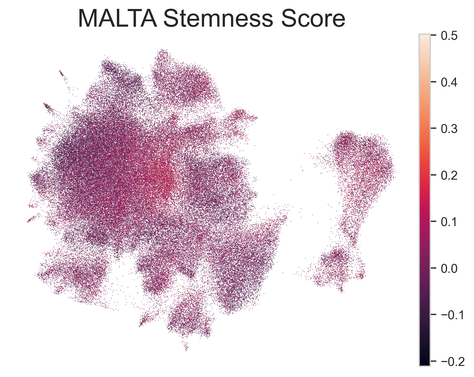

<Figure size 1920x1440 with 0 Axes>

In [38]:
#4 Plot UMAP
sc.pl.umap(tumour,
    color="stemness_score", frameon=False, legend_loc="right margin", title="MALTA Stemness Score")

plt.savefig(rf"{data_dir}/../Figures/stemness_score_UMAP.png",
    dpi=300, bbox_inches="tight")
plt.show()

In [39]:
#5 Define ROR1/EGFR groups using new definition
group_order = ["Double negative", "EGFR only", "ROR1 only", "Double positive"]
group_palette = {
    "Double negative": "#BDBDBD",
    "EGFR only": "#4C72B0",
    "ROR1 only": "#DD8452",
    "Double positive": "#55A868"}

#6 Statistics
# Exclude Normal
tumour_cells = tumour.obs[tumour.obs["condition"].isin(
        ["TN", "HER2+", "ER+"])]

# Double positive vs others
dp = tumour_cells.loc[
    tumour_cells["ROR1_EGFR_group"] == "ROR1/EGFR Double positive", "stemness_score"]

other = tumour_cells.loc[
    tumour_cells["ROR1_EGFR_group"] != "ROR1/EGFR Double positive", "stemness_score"]

stat, p = mannwhitneyu(dp, other, alternative="two-sided")

print(f"Double positive vs all others: p={p:.3e}")
print("Median DP:", dp.median())
print("Median others:", other.median())



Double positive vs all others: p=nan
Median DP: nan
Median others: -0.029979285001754757


/var/folders/kn/dz8n2v_j7cq3qn3h60y7qmwh0000gp/T/ipykernel_67537/3727388400.py:21: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  stat, p = mannwhitneyu(dp, other, alternative="two-sided")


/var/folders/kn/dz8n2v_j7cq3qn3h60y7qmwh0000gp/T/ipykernel_67537/2530861614.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=data,
/var/folders/kn/dz8n2v_j7cq3qn3h60y7qmwh0000gp/T/ipykernel_67537/2530861614.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=data,
/var/folders/kn/dz8n2v_j7cq3qn3h60y7qmwh0000gp/T/ipykernel_67537/2530861614.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=data,


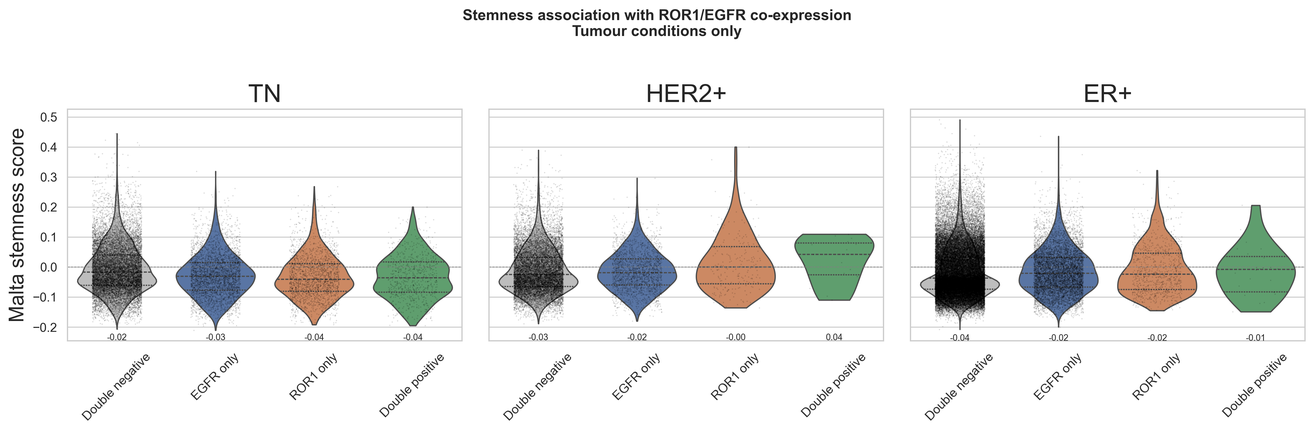

In [40]:
#7 Plotting:  Violin plots by condition
conditions = ["TN", "HER2+", "ER+"]

fig, axes = plt.subplots(1, 3, figsize=(15,5), sharey=True)
for ax, cond in zip(axes, conditions):
    data = tumour.obs[tumour.obs["condition"] == cond]

    sns.violinplot(data=data,
        x="ROR1_EGFR_group", y="stemness_score", order=group_order, palette=group_palette, inner="quartile", cut=0, ax=ax)
    sns.stripplot(data=data,
        x="ROR1_EGFR_group", y="stemness_score", order=group_order, color="black", size=1, alpha=0.15, jitter=0.25, ax=ax)

    # Median labels
    for i, group in enumerate(group_order):
        median = data.loc[data["ROR1_EGFR_group"] == group, "stemness_score"].median()

        if not np.isnan(median):
            ax.text(i, ax.get_ylim()[0], f"{median:.2f}", ha="center", fontsize=7)

    ax.set_title(cond)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
    ax.axhline(0, linestyle="--", linewidth=0.5, color="grey")

axes[0].set_ylabel("Malta stemness score")

plt.suptitle("Stemness association with ROR1/EGFR co-expression\n"
    "Tumour conditions only",
    fontsize=12, fontweight="bold")
plt.tight_layout()

plt.savefig(rf"{data_dir}/../Figures/"
    "Malta_stemness_ROR1_EGFR_coexpression_conditions.png",
    dpi=300, bbox_inches="tight")
plt.show()

ENDE